Experiments
-----------
  EXP 1 : Lap time comparison  (Table 1 + Figure – racelines on two circuits)

  EXP 2 : Computation time     (Table 2)

  EXP 3 : Convergence curves   (Figure – ZORM vs CMA-ES on two circuits)

  EXP 4 : Black-box vehicle model (Table / Figure)


In [6]:
import copy
import configparser
import json
import os
import time
 
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
 
matplotlib.rcParams.update({
    "font.family": "serif",
    "font.size": 9,
    "axes.labelsize": 9,
    "axes.titlesize": 9,
    "legend.fontsize": 8,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
})
 
from OptiLine import solvers, utils, opt_mintime
from OptiLine.KinematicProfs import (
    calc_vel_profile, calc_ax_profile, calc_t_profile,
)
from OptiLine.utils import (
    calc_splines, create_raceline, calc_head_curv_an, import_veh_dyn_info,
    seg_bounds, subsample_reftrack, raceline_from_alpha,
)
from OptiLine.solvers import PointMassOCP

In [ ]:
# ---------------------------------------------------------------------------
# Paths
# ---------------------------------------------------------------------------
MAPS_DIR    = "maps"
GGV_PATH    = os.path.join("input_files", "ggv.csv")
AX_MAX_PATH = os.path.join("input_files", "ax_max_machines.csv")
INI_PATH    = os.path.join("input_files", "racecar.ini")
FIG_DIR     = "paper_figs"
os.makedirs(FIG_DIR, exist_ok=True)
 
# ---------------------------------------------------------------------------
# Circuits
# ---------------------------------------------------------------------------
BENCHMARK_CIRCUITS = {
    "BrandsHatch":     os.path.join(MAPS_DIR, "BrandsHatch",     "BrandsHatch_centerline.csv"),
    "Melbourne": os.path.join(MAPS_DIR, "Melbourne", "Melbourne_centerline.csv"),
    "Catalunya": os.path.join(MAPS_DIR, "Catalunya", "Catalunya_centerline.csv"),
    "Budapest":  os.path.join(MAPS_DIR, "Budapest",  "Budapest_centerline.csv"),
}
 
# ---------------------------------------------------------------------------
# Vehicle parameters (matching racecar.ini)
# ---------------------------------------------------------------------------
VEH = dict(v_max=22.88, m_veh=1000.0, drag_coeff=0.75,
           kappa_bound=0.5, w_veh=1.0, fw=3, dyn_model_exp=1.5)
 
# Shared ZO / CMA-ES hyperparameters
# min_s / max_s are set per-track inside seg_bounds()
HYP = dict(mu=0.0001, h=0.009,t = 1, MC=1, sigma=0.25,
           iterations_ZO=250, iterations_CMA=45, popsize=10, si=1)
# Raceline interpolation step for the FINAL, reported velocity profile.
#
# HYP['si'] is the step the OPTIMISERS work at: it sets how many points the velocity
# profiler integrates over, which is ~97 % of one cost-function evaluation. alpha is
# defined per reference-track NODE and does not depend on it, so re-evaluating the
# finished solution at a finer step is EXACT, not an approximation -- it just removes
# the coarse-integration bias, which is upward and of order +0.05 s per metre of step.
SI_FINAL = 0.25

# ---------------------------------------------------------------------------
# Repeats for the stochastic solvers.
#
# ZORM and CMA-ES are unseeded, so a single run is one sample of a distribution.
# Every zeroth-order number and curve reported in the paper is therefore the mean
# over N_REPEATS independent runs, quoted with its sample standard deviation.
# The deterministic methods (SP, MC, OCP, PM-OCP) are run once.
# Runtime scales linearly in N_REPEATS.
# ---------------------------------------------------------------------------
N_REPEATS = 3

MAP_HYP = {
    "BrandsHatch": dict(bilevel=dict(h = 5e-3, mu=1e-5, t=1, sigma = 0.05), blackbox=dict(h = 3e-4, mu=1e-5, sigma = 0.03)),
    "Melbourne":   dict(bilevel=dict(h = 5e-3, mu=1e-5, t=1, sigma = 0.05), blackbox=dict(h = 3e-4, mu=1e-5, sigma = 0.03)),
    "Catalunya":   dict(bilevel=dict(h = 5e-3, mu=1e-5, t=1, sigma = 0.05), blackbox=dict(h = 3e-4, mu=1e-5, sigma = 0.03)),
    "Budapest":    dict(bilevel=dict(h = 5e-3, mu=1e-5, t=1, sigma = 0.05), blackbox=dict(h = 3e-4, mu=1e-5, sigma = 0.03)),
}

def bilevel_hyp(name):
    """Bilevel (Opt_min_CurvTime) ZO/CMA params for a map: HYP overridden by MAP_HYP[name]['bilevel']."""
    return {**HYP, **MAP_HYP.get(name, {}).get('bilevel', {})}

# ---------------------------------------------------------------------------
# Load OCP parameters from racecar.ini (done once)
# ---------------------------------------------------------------------------
parser = configparser.ConfigParser()
if not parser.read(INI_PATH):
    raise FileNotFoundError(f"racecar.ini not found at {INI_PATH}")
 
OCP_PARS = {}
OCP_PARS["ggv_file"]               = json.loads(parser.get('GENERAL_OPTIONS', 'ggv_file'))
OCP_PARS["ax_max_machines_file"]   = json.loads(parser.get('GENERAL_OPTIONS', 'ax_max_machines_file'))
OCP_PARS["stepsize_opts"]          = json.loads(parser.get('GENERAL_OPTIONS', 'stepsize_opts'))
OCP_PARS["reg_smooth_opts"]        = json.loads(parser.get('GENERAL_OPTIONS', 'reg_smooth_opts'))
OCP_PARS["veh_params"]             = json.loads(parser.get('GENERAL_OPTIONS', 'veh_params'))
OCP_PARS["vel_calc_opts"]          = json.loads(parser.get('GENERAL_OPTIONS', 'vel_calc_opts'))
OCP_PARS["curv_calc_opts"]         = json.loads(parser.get('GENERAL_OPTIONS', 'curv_calc_opts'))
OCP_PARS["optim_opts"]             = json.loads(parser.get('OPTIMIZATION_OPTIONS', 'optim_opts_mintime'))
OCP_PARS["vehicle_params_mintime"] = json.loads(parser.get('OPTIMIZATION_OPTIONS', 'vehicle_params_mintime'))
OCP_PARS["tire_params_mintime"]    = json.loads(parser.get('OPTIMIZATION_OPTIONS', 'tire_params_mintime'))
OCP_PARS["pwr_params_mintime"]     = json.loads(parser.get('OPTIMIZATION_OPTIONS', 'pwr_params_mintime'))
OCP_PARS["vehicle_params_mintime"]["wheelbase"] = (
    OCP_PARS["vehicle_params_mintime"]["wheelbase_front"]
    + OCP_PARS["vehicle_params_mintime"]["wheelbase_rear"]
)
OCP_PARS["optim_opts"]["var_friction"] = None
OCP_PARS["optim_opts"]["warm_start"]   = False
 
# Fill safety limits from GGV
ggv_tmp, _ = import_veh_dyn_info(GGV_PATH, AX_MAX_PATH)
if OCP_PARS["optim_opts"]["ax_pos_safe"] is None:
    OCP_PARS["optim_opts"]["ax_pos_safe"] = float(np.amin(ggv_tmp[:, 1]))
if OCP_PARS["optim_opts"]["ax_neg_safe"] is None:
    OCP_PARS["optim_opts"]["ax_neg_safe"] = float(-np.amin(ggv_tmp[:, 1]))
if OCP_PARS["optim_opts"]["ay_safe"] is None:
    OCP_PARS["optim_opts"]["ay_safe"]     = float(np.amin(ggv_tmp[:, 2]))


# Per-segment spline-length bounds for the bilevel optimiser: each interval is
# constrained to [lo * s_i, hi * s_i] of its OWN initial length (OptiLine >= 0.2.0).
# This replaces the previous global box [min_i s_i, k * max_i s_i], where a single
# short segment lowered the bound for every segment and could make the inner QP
# infeasible.
S_SCALE = (0.6, 1.5)  # (lo, hi) scaling factors for each segment's spline length

# Interior-point corridor constraints (OptiLine >= 0.2.5). The QPs constrain the
# raceline only at the reference-track nodes; the spline interpolated between them
# can bulge outside the track. Constraining a few interior points per segment
# removes that at a small extra QP cost. 0 restores the node-only behaviour of
# OptiLine <= 0.2.2. Passed explicitly everywhere so the setting is reproducible
# rather than inherited from the package default.
N_INTERP_CON = 2

In [ ]:
# ---------------------------------------------------------------------------
# Helpers
# ---------------------------------------------------------------------------
 
# Node picking and the spline-length bounds now come from OptiLine.utils.
#
# NOTE ON A BEHAVIOUR CHANGE. The previous local subsample() was
#     np.unique(np.append(np.arange(0, n, step), n - 1)),
# which forces the LAST centreline index into the node set. Because the loop
# already closes from the last node back to node 0, that leaves a final segment
# roughly 0.45 m long next to ~1.8 m neighbours on every one of the four circuits
# (length ratio ~4.0). The cubic spline through such a node set curls sharply at
# that seam, which corrupts the curvature and hence the velocity profile.
# subsample_reftrack avoids it: 'arc' places nodes at uniform arc length (ratio
# 1.03-1.10 here) and 'index' takes every step-th row without forcing the last
# (ratio 1.07-1.35). Results therefore differ slightly from earlier runs.
SUBSAMPLE = 'arc'          # 'arc' or 'index'
# Measured convergence AND divergence (lap time [s], Solve_Succeeded unless noted):
#
#   circuit        600       800       1000      1700      3000
#   BrandsHatch     --      26.4426   26.4420     --      26.4405
#   Budapest        --      32.7887   32.7915     --      32.7908
#   Catalunya       --      33.2808   33.2806     --      33.2764
#   Melbourne     34.5193     --      34.6408   FAILED    FAILED
#
# The three circuits that converge everywhere agree to under 5 ms between 800 and
# 3000 cells, so a finer mesh buys nothing. MELBOURNE DIVERGES above ~1000 cells:
# IPOPT returns Error_In_Step_Computation and the solution is unusable, but at
# 1400-2500 cells it still returns a plausible-looking 35-38 s, so the failure is
# invisible unless solver_info['success'] is checked -- which run_pm now does by
# raising. At 3000 it degrades visibly (68.63 s, speed capped at 10.5 m/s against
# v_max 22.88).
#
PM_CELLS = 1250

# this notebook allows mild compression and up to 1.8x stretching
SEG_LO, SEG_HI = 0.7, 1.8


# ---------------------------------------------------------------------------
# Aggregation over the N_REPEATS runs of a stochastic solver.
# ---------------------------------------------------------------------------
def agg(vals):
    """(mean, sample std) of a list of scalars. std is 0 for a single run."""
    a = np.asarray(vals, dtype=float)
    return float(a.mean()), (float(a.std(ddof=1)) if a.size > 1 else 0.0)


def pm(mean, sd, p=2, bold=False):
    """LaTeX cell 'mean +- sd'. Wide; needs \\scriptsize in an 11-column table.

    Bolding must happen inside math mode: \\textbf{$x$} leaves $x$ at normal weight.
    """
    body = f"{mean:.{p}f} \\pm {sd:.{p}f}"
    return f"$\\mathbf{{{body}}}$" if bold else f"${body}$"


def pm_compact(mean, sd, p=2, bold=False):
    """LaTeX cell 'mean(sd)', the uncertainty in units of the last digit."""
    body = f"{mean:.{p}f}({int(round(sd * 10 ** p))})"
    return f"\\textbf{{{body}}}" if bold else body


def plain(mean, sd=None, p=2, bold=False):
    """LaTeX cell for a deterministic method."""
    body = f"{mean:.{p}f}"
    return f"\\textbf{{{body}}}" if bold else body


def median_idx(vals):
    """Index of the median run (lower median when N_REPEATS is even).

    Used wherever a single representative object has to be plotted -- a raceline
    in x-y, for instance -- since the pointwise mean of several distinct paths is
    not itself a path any run produced.
    """
    a = np.asarray(vals, dtype=float)
    return int(np.argsort(a)[(a.size - 1) // 2])


def curve_band(curves):
    """Pointwise (mean, std) of equal-length curves, truncated to the shortest."""
    m = min(len(c) for c in curves)
    A = np.vstack([np.asarray(c, dtype=float)[:m] for c in curves])
    sd = A.std(axis=0, ddof=1) if A.shape[0] > 1 else np.zeros(m)
    return A.mean(axis=0), sd


def profile_band(profiles, n=400):
    """(u, mean, std) of (s, v) profiles on a common normalised abscissa u in [0,1].

    Each run optimises a different path, so the profiles do not share an arc
    length. Normalising by lap length puts them on a comparable footing.
    """
    V = []
    u_grid = np.linspace(0.0, 1.0, n)
    for s, v in profiles:
        s = np.asarray(s, dtype=float)
        v = np.asarray(v, dtype=float)
        m = min(len(s), len(v))
        s, v = s[:m], v[:m]
        u = (s - s[0]) / (s[-1] - s[0]) if s[-1] > s[0] else np.linspace(0, 1, m)
        V.append(np.interp(u_grid, u, v))
    A = np.vstack(V)
    sd = A.std(axis=0, ddof=1) if A.shape[0] > 1 else np.zeros(n)
    return u_grid, A.mean(axis=0), sd


def load_track(csv_path, step=4):
    data = np.loadtxt(csv_path, comments='#', delimiter=',')
    return subsample_reftrack(data[:, :4], step=step, mode=SUBSAMPLE)
 
 
def run_sp(reftrack):
    """Shortest path. Returns (laptime_s, raceline, elapsed_s)."""
    t0 = time.time()
    raceline, _, _, _, _, _, t = solvers.ShortestPath(
        n_interp_con=N_INTERP_CON,
        reftrack=reftrack, w_veh=VEH['w_veh'], stepsize=SI_FINAL, v_max=VEH['v_max'],
        plot=False, ggv_import_path=GGV_PATH,
        ax_max_machines_import_path=AX_MAX_PATH,
        dyn_model_exp=VEH['dyn_model_exp'],
    )
    return t[-1], raceline, time.time() - t0

def run_mc(reftrack):
    """Minimum curvature. Returns (laptime_s, raceline, elapsed_s)."""
    t0 = time.time()
    ggv, ax_max = import_veh_dyn_info(GGV_PATH, AX_MAX_PATH)
    min_s, max_s, lengths = seg_bounds(reftrack, lo=SEG_LO, hi=SEG_HI)
    coeffs_x, coeffs_y, M, normvec = calc_splines(
        path=np.vstack((reftrack[:, :2], reftrack[0, :2])),
        el_lengths=lengths, use_dist_scaling=True)
    alpha, _ = solvers.opt_min_curv(
        n_interp_con=N_INTERP_CON,
        reftrack=reftrack, normvectors=normvec, A=M,
        kappa_bound=VEH['kappa_bound'], w_veh=VEH['w_veh'],
        print_debug=False, plot_debug=False, closed=True)
    raceline, kappa, el = raceline_from_alpha(
        reftrack, normvec, alpha, stepsize_interp=SI_FINAL)
    vx = calc_vel_profile(ggv=ggv, ax_max_machines=ax_max,
                          v_max=VEH['v_max'], kappa=kappa,
                          el_lengths=el, closed=True,
                          filt_window=VEH['fw'],
                          dyn_model_exp=VEH['dyn_model_exp'],
                          drag_coeff=VEH['drag_coeff'],
                          m_veh=VEH['m_veh'])
    ax_p = calc_ax_profile(vx_profile=np.append(vx, vx[0]),
                           el_lengths=el, eq_length_output=False)
    t_prof = calc_t_profile(vx_profile=vx, ax_profile=ax_p, el_lengths=el)
    return t_prof[-1], raceline, time.time() - t0
 
 
def run_pm(csv_path):
    """
    Point-mass minimum-lap-time OCP (MLTS-point-mass, via OptiLine.solvers).
    Returns (laptime_s, raceline, elapsed_s).

    Unlike the other runners this takes the FULL centreline rather than the
    subsampled reference track. The sub-sampling is our optimisers' discretisation
    choice, not a property of the circuit, and at step=4 these circuits give
    max|kappa| * spacing of 1.0-2.2 against the 0.5 the solver wants -- at which
    point its reported lap time drifts up to 0.6 % from the path it actually
    returns (0.17 % on the full centreline). Runtime is the same either way,
    because the cost is set by the mesh rather than by the track table.
    """
    t0 = time.time()
    ggv, ax_max = import_veh_dyn_info(GGV_PATH, AX_MAX_PATH)
    full = subsample_reftrack(
        np.loadtxt(csv_path, comments='#', delimiter=',')[:, :4], step=1, mode='arc')
    pm = PointMassOCP(full, ggv,
                      w_veh=VEH['w_veh'], v_max=VEH['v_max'],
                      ax_max_machines=ax_max, dyn_model_exp=VEH['dyn_model_exp'])

    pm.solve(mesh=max(0.05, pm.track_length / PM_CELLS))
    if not pm.solver_info['success']:
        raise RuntimeError(
            f"PointMassOCP did not converge ({pm.solver_info['status']}); "
            f"laptime {pm.laptime:.4f} s is not usable. Lower PM_CELLS for this "
            f"circuit -- see PM_CELLS for the measured per-circuit limits.")
    return pm.laptime, pm.raceline, time.time() - t0


def build_optct(reftrack, ggv_path=GGV_PATH, name=None):
    """
    Instantiate Opt_min_CurvTime with per-track min_s / max_s and per-map
    ZO/CMA hyper-parameters (via bilevel_hyp(name)) + dyn_model_exp from VEH.
    """
    min_s, max_s, lengths = seg_bounds(reftrack, lo=SEG_LO, hi=SEG_HI)
    P = bilevel_hyp(name)
    print(f"    [build_optct] seg lengths: min={lengths.min():.3f} m  "
          f"max={lengths.max():.3f} m  -> min_s={min_s:.3f}  max_s={max_s:.3f}")
    return solvers.Opt_min_CurvTime(
        n_interp_con=N_INTERP_CON,
        reftrack=reftrack, center=reftrack,
        mu=P['mu'], h=P['h'],
        kapb=VEH['kappa_bound'], sfty=VEH['w_veh']/2,
        si=HYP['si'], vm=VEH['v_max'],
        m_veh=VEH['m_veh'], drag_coeff=VEH['drag_coeff'],
        t=P['t'], MC=HYP['MC'],
        s_scale=S_SCALE,
        sigma=P['sigma'],
        iterations_ZO=P['iterations_ZO'],
        iterations_CMA=P['iterations_CMA'],
        popsize=HYP['popsize'],
        ggv_import_path=ggv_path,
        ax_max_machines_import_path=AX_MAX_PATH,
        fw=VEH['fw'],
        dyn_model_exp=VEH['dyn_model_exp'],
    )
 
 
# ---------------------------------------------------------------------------
# Per-circuit OCP track discretisation.
#
# stepsize_reg sets the node spacing of the regression spline that prep_track hands
# to opt_mintime, so it fixes the collocation mesh. One global value does not work
# across these circuits:
#   * at 0.5 m (the racecar.ini default) YasMarina is rejected by prep_track outright
#     -- "at least two spline normals are crossed". Its half-width is a constant
#     1.1 m against corners of ~1.37 m radius, so the local curvature peaks drive
#     1/kappa below the half-width. Coarser nodes smooth those peaks away.
#   * at 1.0 m YasMarina passes, but Catalunya and Budapest stop converging
#     ("Restoration Failed"), while 1.5 and 2.0 converge again -- the dependence is
#     not monotone.
# So the value is set per circuit: the default from racecar.ini for everything that
# works with it, and an override only where it is needed.
#
# NOTE for the write-up: the OCP lap time is NOT mesh-converged here. On Budapest it
# moves 0.58 s between stepsize_reg 1.5 (34.9513 s) and 2.0 (34.3697 s), so the
# chosen mesh has to be quoted alongside the lap time.
# Measured with delta_max = 0.45 and the smooth safe-trajectory constraint of
# OptiLine-Py 0.2.8.2 (lap time [s] / OCP nodes; FAILED = IPOPT restoration failure):
#
#   circuit        0.5              1.0            1.5            2.0
#   BrandsHatch    30.0506 / 710    30.2064 / 355  --             --
#   Melbourne      31.3014 / 943    31.3954 / 472  --             --
#   Catalunya      35.5679 / 828    FAILED         --             --
#   Budapest       34.3547 / 800    FAILED         34.9513 / 267  34.3697 / 200
#   Sepang         40.8465 / 968    40.6320 / 484  41.2898 / 323  FAILED
#   YasMarina      prep_track       FAILED         31.4000 / 262  31.2413 / 197
#
# Mesh sensitivity: Budapest gives 34.3547 s at 0.5 (800 nodes) and 34.3697 s at 2.0
# (200 nodes) -- 15 ms across a 4x mesh change -- so discretisation error is small.
# The 34.9513 s at 1.5 is a different LOCAL OPTIMUM, not mesh error. The mesh selects
# which optimum the solver reaches, so quote it alongside the lap time.
OCP_STEPSIZE_REG = {
    "YasMarina": 1.5,   # 0.5 rejected by prep_track (crossed normals); 1.0 and
                        
}


def ocp_pars_for(name):
    """OCP_PARS with this circuit's stepsize_reg applied (deep copy, safe to mutate)."""
    pars = copy.deepcopy(OCP_PARS)
    if name in OCP_STEPSIZE_REG:
        pars["stepsize_opts"] = dict(pars["stepsize_opts"],
                                     stepsize_reg=OCP_STEPSIZE_REG[name])
    return pars


def run_ocp(reftrack, name=None):
    """
    Minimum-time OCP via opt_mintime.
    Returns (laptime_s, raceline, elapsed_s).
    Timing covers prep_track + opt_mintime solve.
    """
    t0 = time.time()
    pars = ocp_pars_for(name)
 
    reftrack_interp, normvec_interp, a_interp, cx_interp, cy_interp = \
        utils.prep_track(
            reftrack_imp=reftrack,
            reg_smooth_opts=pars["reg_smooth_opts"],
            stepsize_opts=pars["stepsize_opts"],
            debug=False,
            min_width=None,
        )
 
    alpha_opt, v_opt, raceline_opt, _, _, _, s_opt, laptime = \
        opt_mintime.opt_mintime(
            reftrack=reftrack_interp,
            coeffs_x=cx_interp,
            coeffs_y=cy_interp,
            normvectors=normvec_interp,
            pars=pars,
            print_debug=False,
            plot_=False,
        )
 
    return laptime, raceline_opt, time.time() - t0

In [4]:
# ===========================================================================
# EXP 1 & 2 – Lap time + computation time (all 5 methods, 4 circuits)
# ===========================================================================
# Run SP, MC, OCP 
results = {}
for name, path in BENCHMARK_CIRCUITS.items():
    print(f"\n--- {name} ---")
    reftrack = load_track(path, step=4)
    lt_sp, rl_sp, elapsed_sp = run_sp(reftrack)
    lt_mc, rl_mc, elapsed_mc = run_mc(reftrack)
    lt_ocp, rl_ocp, elapsed_ocp = run_ocp(reftrack, name)
    lt_pm, rl_pm, elapsed_pm = run_pm(path)
    print(f"    SP {lt_sp:7.2f} | MC {lt_mc:7.2f} | OCP {lt_ocp:7.2f} | PM-OCP {lt_pm:7.2f} s")
    results[name] = dict(
        lt_sp=lt_sp, lt_mc=lt_mc, lt_ocp=lt_ocp, lt_pm=lt_pm,
        elapsed_sp=elapsed_sp, elapsed_mc=elapsed_mc, elapsed_ocp=elapsed_ocp,
        elapsed_pm=elapsed_pm,
        rl_sp=rl_sp, rl_mc=rl_mc, rl_ocp=rl_ocp, rl_pm=rl_pm,
        reftrack=reftrack,
    )


--- BrandsHatch ---
-0.102041 0.137959 1.1898 1.0

******************************************************************************
This program contains Ipopt, a library for large-scale nonlinear optimization.
 Ipopt is released as open source code under the Eclipse Public License (EPL).
         For more information visit https://github.com/coin-or/Ipopt
******************************************************************************

This is Ipopt version 3.14.11, running with linear solver MUMPS 5.4.1.

Number of nonzeros in equality constraint Jacobian...:   131360
Number of nonzeros in inequality constraint Jacobian.:    42584
Number of nonzeros in Lagrangian Hessian.............:   105776

Total number of variables............................:    17045
                     variables with only lower bounds:        0
                variables with lower and upper bounds:     5685
                     variables with only upper bounds:        0
Total number of equality constraints.....

/tmp/ipykernel_448863/457127347.py:171: RuntimeWarning: PointMassOCP: the reference track is coarse for its curvature (max|kappa| * spacing = 0.79, spacing 0.45 m). The reference line spline will not follow the curve, and the lap time will disagree with the one implied by the returned (x, y) path by roughly 0.3 %. Pass a finer reference track (aim for max|kappa| * spacing <= 0.5).
  pm = PointMassOCP(full, ggv,


Number of mesh points: 1250
Total time to complete the track: 34.64 seconds
    SP   40.16 | MC   40.80 | OCP   31.30 | PM-OCP   34.64 s

--- Catalunya ---
-0.118553 0.121447 1.10724 1.0
This is Ipopt version 3.14.11, running with linear solver MUMPS 5.4.1.

Number of nonzeros in equality constraint Jacobian...:   153190
Number of nonzeros in inequality constraint Jacobian.:    49664
Number of nonzeros in Lagrangian Hessian.............:   123358

Total number of variables............................:    19877
                     variables with only lower bounds:        0
                variables with lower and upper bounds:     6629
                     variables with only upper bounds:        0
Total number of equality constraints.................:    17393
Total number of inequality constraints...............:     9932
        inequality constraints with only lower bounds:      827
   inequality constraints with lower and upper bounds:     6623
        inequality constraints with 

/tmp/ipykernel_448863/457127347.py:171: RuntimeWarning: PointMassOCP: the reference track is coarse for its curvature (max|kappa| * spacing = 0.54, spacing 0.45 m). The reference line spline will not follow the curve, and the lap time will disagree with the one implied by the returned (x, y) path by roughly 0.2 %. Pass a finer reference track (aim for max|kappa| * spacing <= 0.5).
  pm = PointMassOCP(full, ggv,


Number of mesh points: 1250
Total time to complete the track: 33.28 seconds
    SP   36.60 | MC   35.95 | OCP   35.57 | PM-OCP   33.28 s

--- Budapest ---
-0.116988 0.123012 1.11506 1.0
This is Ipopt version 3.14.11, running with linear solver MUMPS 5.4.1.

Number of nonzeros in equality constraint Jacobian...:   148010
Number of nonzeros in inequality constraint Jacobian.:    47984
Number of nonzeros in Lagrangian Hessian.............:   119186

Total number of variables............................:    19205
                     variables with only lower bounds:        0
                variables with lower and upper bounds:     6405
                     variables with only upper bounds:        0
Total number of equality constraints.................:    16805
Total number of inequality constraints...............:     9596
        inequality constraints with only lower bounds:      799
   inequality constraints with lower and upper bounds:     6399
        inequality constraints with o

In [9]:
# ===========================================================================
# EXP 1 & 2 - BZO (ZORM and CMA-ES), averaged over N_REPEATS runs
#
# Both bilevel solvers are stochastic and unseeded. Every reported value is the
# mean over N_REPEATS independent runs with its sample standard deviation, and
# the convergence history of every run is kept so that the figure further down
# can draw a mean curve with a +/- std band.
# ===========================================================================

for name in BENCHMARK_CIRCUITS:
    print(f"\n--- {name} ---")
    reftrack = results[name]['reftrack']

    lt_zo_r, el_zo_r, h_zo_r, rl_zo_r = [], [], [], []
    lt_cma_r, el_cma_r, h_cma_r, rl_cma_r = [], [], [], []

    for q in range(N_REPEATS):
        # ---- BZO-ZORM ----
        t0 = time.time()
        opt = build_optct(reftrack, name=name)
        ds_zo, hist_zo = opt.CurveLenOpt(solver='ZO')
        _si_opt = opt.si; opt.si = SI_FINAL      # exact re-evaluation, same solution
        _, _, _, _, t_zo_prof, rl_zo = opt.generate_kinProfs(ds=ds_zo)
        opt.si = _si_opt
        el_zo_r.append(time.time() - t0)
        lt_zo_r.append(float(t_zo_prof[-1]))
        h_zo_r.append(np.asarray(hist_zo, float))
        rl_zo_r.append(rl_zo)

        # ---- BZO-CMA (same instance, as before) ----
        t0 = time.time()
        ds_cma, hist_cma = opt.CurveLenOpt(solver='CMA')
        _si_opt = opt.si; opt.si = SI_FINAL
        _, _, _, _, t_cma_prof, rl_cma = opt.generate_kinProfs(ds=ds_cma)
        opt.si = _si_opt
        el_cma_r.append(time.time() - t0)
        lt_cma_r.append(float(t_cma_prof[-1]))
        h_cma_r.append(np.asarray(hist_cma, float))
        rl_cma_r.append(rl_cma)

        print(f"    run {q + 1}/{N_REPEATS}:  BZO-ZO={lt_zo_r[-1]:7.3f}s"
              f"   BZO-CMA={lt_cma_r[-1]:7.3f}s")

    lt_zo, sd_zo = agg(lt_zo_r)
    lt_cma, sd_cma = agg(lt_cma_r)
    el_zo, _ = agg(el_zo_r)
    el_cma, _ = agg(el_cma_r)
    i_zo, i_cma = median_idx(lt_zo_r), median_idx(lt_cma_r)

    results[name].update(dict(
        lt_zo=lt_zo,     lt_zo_sd=sd_zo,     lt_zo_runs=lt_zo_r,
        lt_cma=lt_cma,   lt_cma_sd=sd_cma,   lt_cma_runs=lt_cma_r,
        elapsed_zo=el_zo, elapsed_cma=el_cma,
        rl_zo=rl_zo_r[i_zo],      # median run: a mean of distinct paths is not a path
        rl_cma=rl_cma_r[i_cma],
        hist_zo=h_zo_r[i_zo],     hist_cma=h_cma_r[i_cma],
        hist_zo_runs=h_zo_r,      hist_cma_runs=h_cma_r,
    ))
    print(f"  BZO-ZO={lt_zo:.2f}+-{sd_zo:.2f}s ({el_zo:.1f}s)   "
          f"BZO-CMA={lt_cma:.2f}+-{sd_cma:.2f}s ({el_cma:.1f}s)")



--- BrandsHatch ---
    [build_optct] seg lengths: min=1.777 m  max=1.827 m  -> min_s=1.244  max_s=3.289
    run 1/3:  BZO-ZO= 28.700s   BZO-CMA= 28.620s
    [build_optct] seg lengths: min=1.777 m  max=1.827 m  -> min_s=1.244  max_s=3.289
    run 2/3:  BZO-ZO= 28.595s   BZO-CMA= 28.756s
    [build_optct] seg lengths: min=1.777 m  max=1.827 m  -> min_s=1.244  max_s=3.289
    run 3/3:  BZO-ZO= 28.636s   BZO-CMA= 28.840s
  BZO-ZO=28.64+-0.05s (136.0s)   BZO-CMA=28.74+-0.11s (86.5s)

--- Melbourne ---
    [build_optct] seg lengths: min=1.627 m  max=1.790 m  -> min_s=1.139  max_s=3.221
    run 1/3:  BZO-ZO= 38.914s   BZO-CMA= 39.314s
    [build_optct] seg lengths: min=1.627 m  max=1.790 m  -> min_s=1.139  max_s=3.221
    run 2/3:  BZO-ZO= 39.091s   BZO-CMA= 39.299s
    [build_optct] seg lengths: min=1.627 m  max=1.790 m  -> min_s=1.139  max_s=3.221
    run 3/3:  BZO-ZO= 39.250s   BZO-CMA= 39.156s
  BZO-ZO=39.08+-0.17s (154.1s)   BZO-CMA=39.26+-0.09s (134.0s)

--- Catalunya ---
    [build_o

## EXP 5–8 — BBA, Init Comparison, Refinement, Comfort Cost

  EXP 5 : BBA (Blackbox_raceline) benchmark  — all 4 circuits (Tables 1 & 2 BBA columns)
  EXP 6 : Initialisation-mode comparison     — BBA-ZO on Catalunya (Section 7.3 figure)
  EXP 7 : Iterative path refinement          — variants A/B/C on Catalunya (Table 3 + Fig)
  EXP 8 : Custom comfort cost                — BBA-ZO on Budapest (Table 4)

In [10]:
# ---------------------------------------------------------------------------
# BBA helper — wraps Blackbox_raceline with shared vehicle params
# ---------------------------------------------------------------------------

BBA_HYP = dict(
    mu=0.00001,           # ZO perturbation magnitude
    h=0.0001,           # gradient step size
    t=12,               # directions averaged per estimate
    grad_type='noth',  # forward finite-difference
    iterations=2000,    # ZO gradient steps
    n_iter_cma=500,     # CMA generations
    popsize=12,        # CMA population size
    sigma = 0.005,     # CMA-ES exploration parameter
    n_jobs=12,         # parallel workers for ZO and CMA-ES
)


def blackbox_hyp(name):
    """Blackbox ZO/CMA params for a map: BBA_HYP overridden by MAP_HYP[name]['blackbox']."""
    return {**BBA_HYP, **MAP_HYP.get(name, {}).get('blackbox', {})}


def build_bba(reftrack, init='mincurv', n_iter=None, cost_fn=None, seed=None, name=None):
    """Instantiate Blackbox_raceline with shared vehicle / per-map hyper-parameters."""
    B = blackbox_hyp(name)
    ggv_bb, ax_max_bb = import_veh_dyn_info(GGV_PATH, AX_MAX_PATH)
    return solvers.Blackbox_raceline(
        n_interp_con=N_INTERP_CON,
        reftrack=reftrack,
        ggv=ggv_bb,
        ax_max_machines=ax_max_bb,
        sfty=VEH['w_veh']/2,  # half-width: 0.5 m per side
        v_max=VEH['v_max'],
        si=HYP['si'],
        fw=VEH['fw'],
        m_veh=VEH['m_veh'],
        drag_coeff=VEH['drag_coeff'],
        dyn_model_exp=VEH['dyn_model_exp'],
        cost_fn=cost_fn,
        init=init,
        oracle='gaussian',
        mu=B['mu'],
        h=B['h'],
        t=BBA_HYP['t'],
        grad_type=BBA_HYP['grad_type'],
        iterations=n_iter if n_iter is not None else BBA_HYP['iterations'],
        kappa_bound=VEH['kappa_bound'],
        seed=seed,
        n_jobs=BBA_HYP['n_jobs'],
    )

print("build_bba() helper defined.")

build_bba() helper defined.


In [12]:
# ===========================================================================
# EXP 5 - BBA (Blackbox_raceline) benchmark, averaged over N_REPEATS runs
#         Both mincurv AND shortest initialisations
#
# The warm start itself is deterministic for both init modes (each is a QP
# solution), so only the search is repeated. Per-run lap times, histories and
# velocity profiles are all retained for the aggregated figures.
# ===========================================================================
print("" + "=" * 65)
print(f"  EXP 5: BBA benchmark (4 circuits, ZO + CMA, mc + sp init, "
      f"{N_REPEATS} runs each)")
print("=" * 65)

bba_conv_data = {}   # for the convergence figure

_suf = {"mincurv": "mc", "shortest": "sp"}

for name, path in BENCHMARK_CIRCUITS.items():
    print(f"--- {name} ---")
    reftrack = load_track(path, step=4)
    B = blackbox_hyp(name)

    for init_mode in ["mincurv", "shortest"]:
        suf = _suf[init_mode]
        lt_zo_r, el_zo_r, h_zo_r, rl_zo_r, prof_zo_r = [], [], [], [], []
        lt_cma_r, el_cma_r, h_cma_r, rl_cma_r = [], [], [], []
        s_init = vx_init = rl_init = None

        for q in range(N_REPEATS):
            # ---- BBA-ZO ----
            bba_zo = build_bba(reftrack, init=init_mode,
                               n_iter=BBA_HYP["iterations"], seed=None, name=name)
            t0 = time.time()
            alpha_zo, hist_zo = bba_zo.find_alpha(
                solver="ZO", verbose=(q == 0), print_every=500)
            _si_opt = bba_zo.si; bba_zo.si = SI_FINAL   # exact re-evaluation
            s_zo, vx_zo, _, _, t_prof_zo, rl_bba_zo = bba_zo.generate_raceline(alpha_zo)
            if q == 0:   # alpha_0 is the same every run for both init modes
                s_init, vx_init, _, _, _, rl_init = \
                    bba_zo.generate_raceline(bba_zo.alpha_0)
            bba_zo.si = _si_opt
            el_zo_r.append(time.time() - t0)
            lt_zo_r.append(float(t_prof_zo[-1]))
            h_zo_r.append(np.asarray(hist_zo, float))
            rl_zo_r.append(rl_bba_zo)
            prof_zo_r.append((s_zo, vx_zo))

            # ---- BBA-CMA ----
            bba_cma = build_bba(reftrack, init=init_mode,
                                n_iter=BBA_HYP["n_iter_cma"], seed=None, name=name)
            t0 = time.time()
            alpha_cma, hist_cma = bba_cma.find_alpha(
                solver="CMA", n_iter=BBA_HYP["n_iter_cma"],
                popsize=BBA_HYP["popsize"], sigma=B["sigma"],
                verbose=(q == 0), print_every=100)
            _si_opt = bba_cma.si; bba_cma.si = SI_FINAL
            s_cma, vx_cma, _, _, t_prof_cma, rl_bba_cma = \
                bba_cma.generate_raceline(alpha_cma)
            bba_cma.si = _si_opt
            el_cma_r.append(time.time() - t0)
            lt_cma_r.append(float(t_prof_cma[-1]))
            h_cma_r.append(np.asarray(hist_cma, float))
            rl_cma_r.append(rl_bba_cma)

            print(f"    [{init_mode}] run {q + 1}/{N_REPEATS}: "
                  f"ZO={lt_zo_r[-1]:7.3f}s  CMA={lt_cma_r[-1]:7.3f}s")

        lt_zo, sd_zo = agg(lt_zo_r)
        lt_cma, sd_cma = agg(lt_cma_r)
        el_zo, _ = agg(el_zo_r)
        el_cma, _ = agg(el_cma_r)
        i_zo, i_cma = median_idx(lt_zo_r), median_idx(lt_cma_r)

        results[name].update({
            f"lt_bba_zo_{suf}":        lt_zo,
            f"lt_bba_zo_sd_{suf}":     sd_zo,
            f"lt_bba_zo_runs_{suf}":   lt_zo_r,
            f"lt_bba_cma_{suf}":       lt_cma,
            f"lt_bba_cma_sd_{suf}":    sd_cma,
            f"lt_bba_cma_runs_{suf}":  lt_cma_r,
            f"elapsed_bba_zo_{suf}":   el_zo,
            f"elapsed_bba_cma_{suf}":  el_cma,
            # median run, for anything plotted in x-y
            f"rl_bba_zo_{suf}":        rl_zo_r[i_zo],
            f"rl_bba_cma_{suf}":       rl_cma_r[i_cma],
            f"hist_bba_zo_{suf}":      h_zo_r[i_zo],
            f"hist_bba_cma_{suf}":     h_cma_r[i_cma],
            f"hist_bba_zo_runs_{suf}":  h_zo_r,
            f"hist_bba_cma_runs_{suf}": h_cma_r,
            # velocity profiles: the warm start is deterministic, the result is not
            f"s_bba_zo_init_{suf}":    s_init,
            f"vx_bba_zo_init_{suf}":   vx_init,
            f"rl_bba_zo_init_{suf}":   rl_init,
            f"s_bba_zo_opt_{suf}":     prof_zo_r[i_zo][0],
            f"vx_bba_zo_opt_{suf}":    prof_zo_r[i_zo][1],
            f"prof_bba_zo_runs_{suf}": prof_zo_r,
        })

        if init_mode == "mincurv":
            bba_conv_data[name] = dict(
                zo=h_zo_r[i_zo], cma=h_cma_r[i_cma],
                zo_runs=h_zo_r, cma_runs=h_cma_r,
                lt_mc=results[name]["lt_mc"])

        print(f"  [{init_mode}] BBA-ZO  lap={lt_zo:.2f}+-{sd_zo:.2f}s  time={el_zo:.1f}s")
        print(f"  [{init_mode}] BBA-CMA lap={lt_cma:.2f}+-{sd_cma:.2f}s  time={el_cma:.1f}s")


  EXP 5: BBA benchmark (4 circuits, ZO + CMA, mc + sp init, 3 runs each)
--- BrandsHatch ---
[Blackbox_raceline/ZO] init  laptime = 29.8110 s  (init='mincurv', N=195)
  iter  500/2000:  laptime = 27.5546 s   best = 27.5546 s
  iter 1000/2000:  laptime = 27.3452 s   best = 27.3367 s
  iter 1500/2000:  laptime = 27.2602 s   best = 27.2450 s
  iter 2000/2000:  laptime = 27.2297 s   best = 27.1958 s
[Blackbox_raceline/ZO] done  best laptime = 27.1958 s  (improvement = 2.6152 s)
[Blackbox_raceline/CMA] init  laptime = 29.8110 s  (init='mincurv', N=195)
  gen   100/500:  gen_best = 30.2415 s   best = 29.8110 s
  gen   200/500:  gen_best = 29.4129 s   best = 29.2152 s
  gen   300/500:  gen_best = 28.6379 s   best = 28.5831 s
  gen   400/500:  gen_best = 28.0958 s   best = 28.0611 s
  gen   500/500:  gen_best = 27.7955 s   best = 27.7955 s
[Blackbox_raceline/CMA] done  best laptime = 27.7955 s  (improvement = 2.0155 s)
    [mincurv] run 1/3: ZO= 27.180s  CMA= 27.679s
    [mincurv] run 2/3: ZO=


% ===== TABLE 1 (pm form, needs \scriptsize) =====
\begin{table*}[t]
  \centering
  \caption{Estimated lap times (s). Zeroth-order entries are the mean  over 3 runs $\pm$ one sample standard deviation;  SP, MC, PM-OCP and OCP are deterministic.  Bold = best gradient-free result. mc=mincurv init, sp=shortest init.}
  \label{tab:laptimes}
  \scriptsize
  \begin{tabular}{lcccccccccc}
    \toprule
    Circuit & SP & MC & BZO-ZO & BZO-CMA & BBA-ZO(mc) & BBA-CMA(mc) & BBA-ZO(sp) & BBA-CMA(sp) & PM-OCP & OCP \\
    \midrule
    BrandsHatch & 30.26 & 29.52 & $28.64 \pm 0.05$ & $28.74 \pm 0.11$ & $\mathbf{27.16 \pm 0.02}$ & $27.76 \pm 0.07$ & $28.51 \pm 0.14$ & $28.96 \pm 0.05$ & 26.44 & 30.05 \\
    Melbourne & 40.16 & 40.80 & $39.08 \pm 0.17$ & $39.26 \pm 0.09$ & $\mathbf{36.83 \pm 0.04}$ & $38.41 \pm 0.18$ & $38.48 \pm 0.10$ & $39.82 \pm 0.24$ & 34.64 & 31.30 \\
    Catalunya & 36.60 & 35.95 & $35.28 \pm 0.07$ & $35.39 \pm 0.13$ & $\mathbf{34.35 \pm 0.23}$ & $34.99 \pm 0.20$ & $35.43 \pm 0.

/tmp/ipykernel_448863/2244106988.py:94: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "-" (-> linestyle='-'). The keyword argument will take precedence.
  ax.plot(r['rl_ocp'][:, 0], r['rl_ocp'][:, 1],


Saved: paper_figs/fig_racelines.pdf


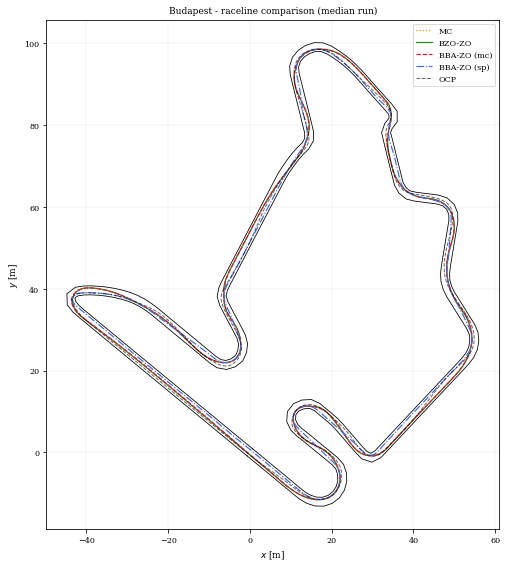

In [13]:
# ---- LaTeX Tables 1 & 2 -----------------------------------------------------
# Zeroth-order entries are mean +- sample std over N_REPEATS runs; SP, MC,
# PM-OCP and OCP are deterministic and run once.
#
# Two formats are printed. The "pm" form needs \scriptsize to fit an 11-column
# table* on a letter page; the compact form, mean(sd) with the uncertainty in
# units of the last digit, fits at normal size.
# -----------------------------------------------------------------------------
_ZO_KEYS = [('lt_zo', 'lt_zo_sd'), ('lt_cma', 'lt_cma_sd'),
            ('lt_bba_zo_mc', 'lt_bba_zo_sd_mc'), ('lt_bba_cma_mc', 'lt_bba_cma_sd_mc'),
            ('lt_bba_zo_sp', 'lt_bba_zo_sd_sp'), ('lt_bba_cma_sp', 'lt_bba_cma_sd_sp')]


def _table1(cell):
    print(r"\begin{table*}[t]")
    print(r"  \centering")
    print(r"  \caption{Estimated lap times (s). Zeroth-order entries are the mean"
          rf"  over {N_REPEATS} runs $\pm$ one sample standard deviation;"
          r"  SP, MC, PM-OCP and OCP are deterministic."
          r"  Bold = best gradient-free result. mc=mincurv init, sp=shortest init.}")
    print(r"  \label{tab:laptimes}")
    print(r"  \scriptsize")
    print(r"  \begin{tabular}{lcccccccccc}")
    print(r"    \toprule")
    print(r"    Circuit & SP & MC & BZO-ZO & BZO-CMA"
          r" & BBA-ZO(mc) & BBA-CMA(mc) & BBA-ZO(sp) & BBA-CMA(sp) & PM-OCP & OCP \\")
    print(r"    \midrule")
    for name, r in results.items():
        # every gradient-free column, in print order; exactly one is bolded
        gf = [(r['lt_sp'], None), (r['lt_mc'], None)] + \
             [(r[m], r.get(sdk, 0.0)) for m, sdk in _ZO_KEYS]
        i_best = int(np.argmin([v for v, _ in gf]))
        out = []
        for i, (v, sd) in enumerate(gf):
            fn = plain if sd is None else cell
            out.append(fn(v, sd, bold=(i == i_best)))
        print(f"    {name} & " + " & ".join(out)
              + f" & {r['lt_pm']:.2f} & {r['lt_ocp']:.2f} " + r"\\")
    print(r"    \bottomrule")
    print(r"  \end{tabular}")
    print(r"\end{table*}")


print("\n% ===== TABLE 1 (pm form, needs \\scriptsize) =====")
_table1(pm)
print("\n% ===== TABLE 1 (compact form, fits at normal size) =====")
_table1(pm_compact)

print("\n% ===== TABLE 2: Computation times =====")
print(r"\begin{table*}[t]")
print(r"  \centering")
print(r"  \caption{Wall-clock computation times. SP and MC are single QP"
      r" solves, reported in ms; all other methods are iterative and reported"
      rf" in s. Zeroth-order entries are the mean over {N_REPEATS} runs."
      r" Column labels as in Table~\ref{tab:laptimes}.}")
print(r"  \label{tab:compute}")
print(r"  \scriptsize")
print(r"  \begin{tabular}{lcccccccccc}")
print(r"    \toprule")
print(r"    Circuit & SP & MC & BZO-ZO & BZO-CMA"
      r" & BBA-ZO(mc) & BBA-CMA(mc) & BBA-ZO(sp) & BBA-CMA(sp)"
      r" & PM-OCP & OCP \\")
print(r"    \midrule")
for name, r in results.items():
    print(f"    {name}"
          f" & {r['elapsed_sp'] * 1e3:.0f} & {r['elapsed_mc'] * 1e3:.0f}"
          f" & {r['elapsed_zo']:.1f} & {r['elapsed_cma']:.1f}"
          f" & {r['elapsed_bba_zo_mc']:.1f} & {r['elapsed_bba_cma_mc']:.1f}"
          f" & {r['elapsed_bba_zo_sp']:.1f} & {r['elapsed_bba_cma_sp']:.1f}"
          f" & {r['elapsed_pm']:.1f} & {r['elapsed_ocp']:.1f} " + r"\\")
print(r"    \bottomrule")
print(r"  \end{tabular}")
print(r"\end{table*}")

# ---- BBA raceline overlay on Budapest (median run of each method) ----
print("\n--- BBA raceline overlay on Budapest (median run) ---")
fig, ax = plt.subplots(figsize=(8, 8))
r = results['Budapest']
rt = r['reftrack']
_, _, lengths = seg_bounds(rt)
_, _, _, nv = calc_splines(
    path=np.vstack((rt[:, :2], rt[0, :2])),
    el_lengths=lengths, use_dist_scaling=True)
bound_r = np.vstack((rt[:, :2] + rt[:, 2:3] * nv, rt[0, :2] + rt[0, 2] * nv[0]))
bound_l = np.vstack((rt[:, :2] - rt[:, 3:4] * nv, rt[0, :2] - rt[0, 3] * nv[0]))
ax.plot(bound_r[:, 0], bound_r[:, 1], 'k-', lw=0.8)
ax.plot(bound_l[:, 0], bound_l[:, 1], 'k-', lw=0.8)
ax.plot(r['rl_mc'][:, 0], r['rl_mc'][:, 1], ':', color='darkorange', lw=1.2, label='MC')
ax.plot(r['rl_zo'][:, 0], r['rl_zo'][:, 1], '-', color='forestgreen', lw=1.2, label='BZO-ZO')
ax.plot(r['rl_bba_zo_mc'][:, 0], r['rl_bba_zo_mc'][:, 1],
        '--', color='crimson', lw=1.2, label='BBA-ZO (mc)')
ax.plot(r['rl_bba_zo_sp'][:, 0], r['rl_bba_zo_sp'][:, 1],
        '-.', color='royalblue', lw=1.2, label='BBA-ZO (sp)')
ax.plot(r['rl_ocp'][:, 0], r['rl_ocp'][:, 1],
        '-', color='black', lw=1.0, ls='--', label='OCP', alpha=0.6)
ax.set_title('Budapest - raceline comparison (median run)')
ax.set_aspect('equal')
ax.set_xlabel('$x$ [m]'); ax.set_ylabel('$y$ [m]')
ax.legend(framealpha=0.7); ax.grid(True, lw=0.3, alpha=0.5)
plt.tight_layout()
fpath = os.path.join(FIG_DIR, 'fig_racelines.pdf')
plt.savefig(fpath)
print(f"Saved: {fpath}")
plt.show()



--- Convergence figure (mean of 3 runs, +/- 1 std band) ---
Saved: paper_figs/fig_convergence.pdf


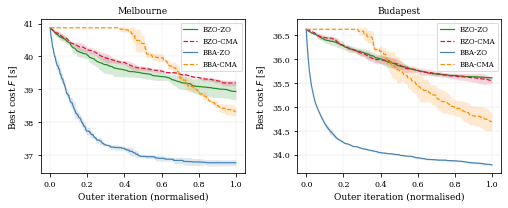

In [14]:
# ===========================================================================
# fig_convergence.pdf - BZO-ZO, BZO-CMA, BBA-ZO, BBA-CMA on Melbourne and Budapest
#
# Each curve is the pointwise mean over N_REPEATS runs, with a shaded +/- one
# standard deviation band. The iteration axis is normalised because the bilevel
# and blackbox budgets differ.
# ===========================================================================
print(f"\n--- Convergence figure (mean of {N_REPEATS} runs, +/- 1 std band) ---")

_SERIES = [('hist_zo_runs',      'forestgreen', '-',  'BZO-ZO'),
           ('hist_cma_runs',     'crimson',     '--', 'BZO-CMA'),
           ('zo_runs',           'steelblue',   '-',  'BBA-ZO'),
           ('cma_runs',          'darkorange',  '--', 'BBA-CMA')]

fig, axes = plt.subplots(1, 2, figsize=(7.16, 3.0))
for ax, name in zip(axes, ['Melbourne', 'Budapest']):
    _r = results[name]
    _b = bba_conv_data[name]
    for key, colour, style, label in _SERIES:
        runs = _r.get(key) if key.startswith('hist_') else _b.get(key)
        if not runs:
            continue
        mu, sd = curve_band(runs)
        x = np.linspace(0, 1, len(mu))
        ax.plot(x, mu, style, color=colour, lw=1.2, label=label)
        if np.any(sd > 0):
            ax.fill_between(x, mu - sd, mu + sd, color=colour, alpha=0.18, lw=0)
    ax.set_title(name)
    ax.set_xlabel('Outer iteration (normalised)')
    ax.set_ylabel(r'Best cost $F$ [s]')
    ax.legend(framealpha=0.7, fontsize=7)
    ax.grid(True, lw=0.3, alpha=0.5)

plt.tight_layout()
fpath = os.path.join(FIG_DIR, 'fig_convergence.pdf')
plt.savefig(fpath)
print(f"Saved: {fpath}")
plt.show()



  EXP 6: BBA-ZO initialisation comparison (Catalunya, 3 runs)
  init='zero' ...
    run 1/3: init=37.8253s  ZO final=36.3276s
    run 2/3: init=37.8253s  ZO final=36.1268s
    run 3/3: init=37.8253s  ZO final=36.1087s
    => init 37.8253+-0.0000s   ZO final 36.1877+-0.1215s
  init='random' ...
    run 1/3: init=89.5722s  ZO final=62.2543s
    run 2/3: init=83.1995s  ZO final=46.0239s
    run 3/3: init=84.3910s  ZO final=43.5965s
    => init 85.7209+-3.3881s   ZO final 50.6249+-10.1442s
  init='mincurv' ...
    run 1/3: init=35.9535s  ZO final=34.6603s
    run 2/3: init=35.9535s  ZO final=35.0019s
    run 3/3: init=35.9535s  ZO final=34.2643s
    => init 35.9535+-0.0000s   ZO final 34.6421+-0.3691s
  init='shortest' ...
    run 1/3: init=36.6019s  ZO final=35.4534s
    run 2/3: init=36.6019s  ZO final=35.4202s
    run 3/3: init=36.6019s  ZO final=35.3686s
    => init 36.6019+-0.0000s   ZO final 35.4141+-0.0427s


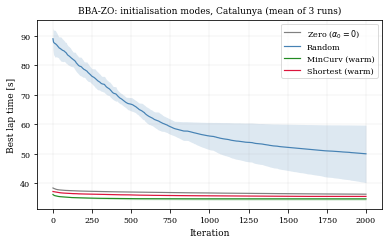


% ===== EXP 6 Summary =====
Mode                    Init (s)        ZO final (s)   Saved (s)
  zero             37.8253+-0.0000     36.1877+-0.1215     +1.6376
  random           85.7209+-3.3881     50.6249+-10.1442    +35.0960
  mincurv          35.9535+-0.0000     34.6421+-0.3691     +1.3113
  shortest         36.6019+-0.0000     35.4141+-0.0427     +1.1878


In [15]:
# ===========================================================================
# EXP 6 - BBA-ZO initialisation comparison on Catalunya, over N_REPEATS runs
#
# 'zero', 'mincurv' and 'shortest' have a deterministic warm start, so only the
# search varies between runs; 'random' draws a new alpha_0 each time, so its
# initial lap time varies too and is aggregated as well.
# ===========================================================================
print("\n" + "=" * 65)
print(f"  EXP 6: BBA-ZO initialisation comparison (Catalunya, {N_REPEATS} runs)")
print("=" * 65)

INIT_MODES = ['zero', 'random', 'mincurv', 'shortest']
INIT_COLORS = {'zero': 'gray', 'random': 'steelblue',
               'mincurv': 'forestgreen', 'shortest': 'crimson'}
INIT_LABELS = {'zero': r'Zero ($\alpha_0 = 0$)', 'random': r'Random',
               'mincurv': r'MinCurv (warm)', 'shortest': r'Shortest (warm)'}

reftrack_cat = load_track(BENCHMARK_CIRCUITS['Catalunya'], step=4)
init_results = {}
cma_profiles = {}

for mode in INIT_MODES:
    print(f"  init='{mode}' ...", flush=True)
    lt_r, lti_r, h_r, prof_r, profi_r, rl_r, rli_r = [], [], [], [], [], [], []

    for q in range(N_REPEATS):
        # name= is required: without it blackbox_hyp() falls back to the global
        # BBA_HYP and MAP_HYP['Catalunya'] is silently ignored.
        bba = build_bba(reftrack_cat, init=mode,
                        n_iter=BBA_HYP['iterations'], seed=None, name='Catalunya')

        # alpha_0 before optimisation, reported at SI_FINAL like every other method
        _si_opt = bba.si; bba.si = SI_FINAL
        s_i, vx_i, _, _, t_i, rl_i = bba.generate_raceline(bba.alpha_0)
        bba.si = _si_opt

        alpha, hist = bba.find_alpha(solver='ZO', verbose=False)
        bba.si = SI_FINAL
        s_z, vx_z, _, _, t_prof, rl_z = bba.generate_raceline(alpha)
        bba.si = _si_opt

        lt_r.append(float(t_prof[-1])); lti_r.append(float(t_i[-1]))
        h_r.append(np.asarray(hist, float))
        prof_r.append((s_z, vx_z)); profi_r.append((s_i, vx_i))
        rl_r.append(rl_z); rli_r.append(rl_i)
        print(f"    run {q + 1}/{N_REPEATS}: init={lti_r[-1]:.4f}s  "
              f"ZO final={lt_r[-1]:.4f}s")

    lt, lt_sd = agg(lt_r)
    lti, lti_sd = agg(lti_r)
    j = median_idx(lt_r)
    init_results[mode] = dict(
        history=h_r[j], history_runs=h_r,
        lt=lt, lt_sd=lt_sd, lt_runs=lt_r, rl=rl_r[j],
        lt_init=lti, lt_init_sd=lti_sd,
        s_init=profi_r[j][0], vx_init=profi_r[j][1], rl_init=rli_r[j],
        s_zo=prof_r[j][0], vx_zo=prof_r[j][1],
        prof_runs=prof_r, prof_init_runs=profi_r,
    )
    print(f"    => init {lti:.4f}+-{lti_sd:.4f}s   "
          f"ZO final {lt:.4f}+-{lt_sd:.4f}s")

# ---- Convergence plot: mean +/- std per init mode ----
fig, ax = plt.subplots(figsize=(5.5, 3.5))
for mode, dd in init_results.items():
    mu, sd = curve_band(dd['history_runs'])
    x = np.arange(len(mu))
    ax.plot(x, mu, color=INIT_COLORS[mode], lw=1.2, label=INIT_LABELS[mode])
    if np.any(sd > 0):
        ax.fill_between(x, mu - sd, mu + sd, color=INIT_COLORS[mode], alpha=0.18, lw=0)
ax.set_xlabel('Iteration')
ax.set_ylabel(r'Best lap time [s]')
ax.set_title(f'BBA-ZO: initialisation modes, Catalunya (mean of {N_REPEATS} runs)')
ax.legend(framealpha=0.7)
ax.grid(True, lw=0.3, alpha=0.5)
plt.tight_layout()
plt.show()

# ---- Summary table ----
print("\n% ===== EXP 6 Summary =====")
print(f"{'Mode':<12s}  {'Init (s)':>18s}  {'ZO final (s)':>18s}  {'Saved (s)':>10s}")
for mode, dd in init_results.items():
    delta = dd['lt_init'] - dd['lt']
    print(f"  {mode:<12s}  {dd['lt_init']:>10.4f}+-{dd['lt_init_sd']:<6.4f}  "
          f"{dd['lt']:>10.4f}+-{dd['lt_sd']:<6.4f}  {delta:>+10.4f}")



--- EXP 6: velocity profile comparison (Catalunya) ---
Saved: paper_figs/fig_init_velocity.pdf


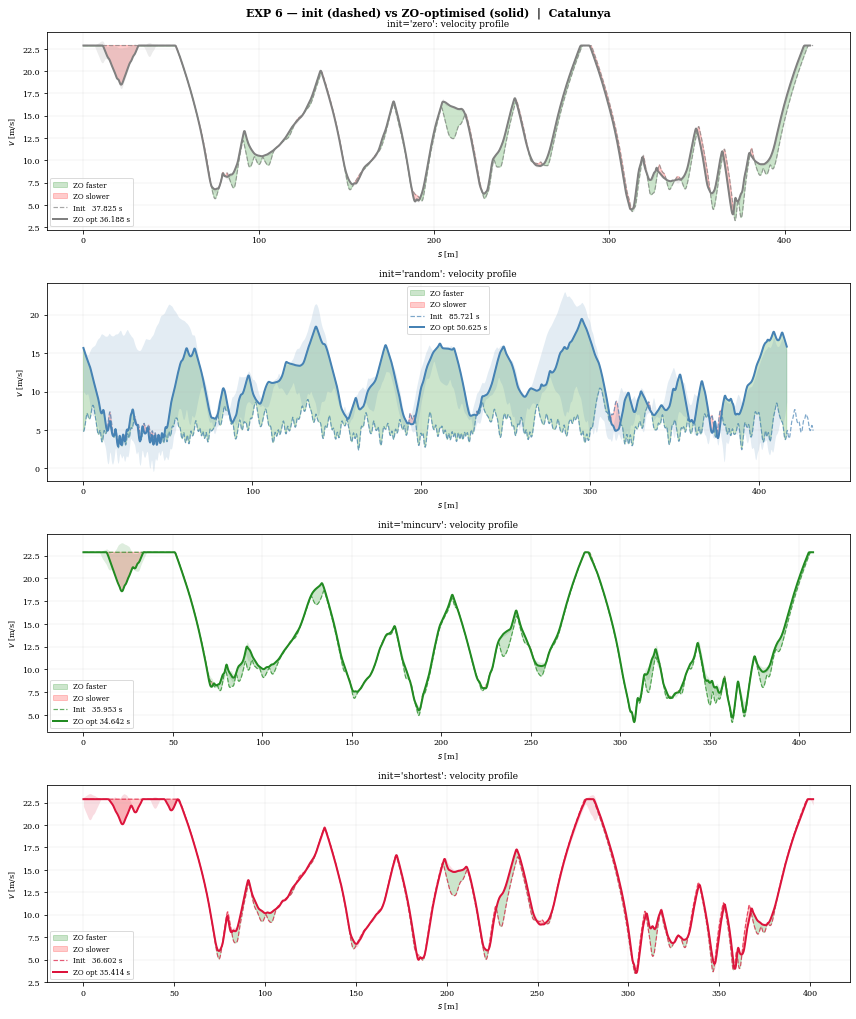

In [16]:
# ===========================================================================
# EXP 6 — Velocity profile comparison: init (dashed) vs ZO-optimised (solid)
#          Per init mode, 2-column: raceline layout | velocity + shaded regions
#          Green = ZO faster, Red = ZO slower
# ===========================================================================
print("\n--- EXP 6: velocity profile comparison (Catalunya) ---")

# Build track boundaries once for the left column
rt_cat = reftrack_cat
_, _, cat_lengths = seg_bounds(rt_cat)
_, _, _, cat_nv = calc_splines(
    path=np.vstack((rt_cat[:, :2], rt_cat[0, :2])),
    el_lengths=cat_lengths, use_dist_scaling=True)
cat_bnd_r = np.vstack((rt_cat[:, :2] + rt_cat[:, 2:3] * cat_nv,
                        rt_cat[0, :2] + rt_cat[0, 2] * cat_nv[0]))
cat_bnd_l = np.vstack((rt_cat[:, :2] - rt_cat[:, 3:4] * cat_nv,
                        rt_cat[0, :2] - rt_cat[0, 3] * cat_nv[0]))

n_modes = len(INIT_MODES)
fig, axes = plt.subplots(n_modes, 1, figsize=(12, 3.6 * n_modes))
fig.suptitle(
    "EXP 6 — init (dashed) vs ZO-optimised (solid)  |  Catalunya",
    fontsize=11, fontweight='bold')

for row, mode in enumerate(INIT_MODES):
    d   = init_results[mode]
    clr = INIT_COLORS[mode]

    s_i,  vx_i  = d['s_init'], d['vx_init']
    s_z,  vx_z  = d['s_zo'],   d['vx_zo']
    rl_i, rl_z  = d['rl_init'], d['rl']
    t_i,  t_z   = d['lt_init'], d['lt']
    delta_t      = t_i - t_z

    # # ── Left: raceline map ────────────────────────────────────
    # ax_m = axes[row, 0]
    # ax_m.plot(cat_bnd_r[:, 0], cat_bnd_r[:, 1], 'k-', lw=0.8)
    # ax_m.plot(cat_bnd_l[:, 0], cat_bnd_l[:, 1], 'k-', lw=0.8)
    # ax_m.plot(rl_i[:, 0], rl_i[:, 1], color=clr, ls='--', lw=1.2, alpha=0.7,
    #           label=f"Init   {t_i:.3f} s")
    # ax_m.plot(rl_z[:, 0], rl_z[:, 1], color=clr, ls='-',  lw=2.0,
    #           label=f"ZO opt {t_z:.3f} s  ({delta_t:+.3f} s)")
    # if mode in cma_profiles:
    #     _, _, _, _, t_c, rl_c = cma_profiles[mode]
    #     dc = t_i - t_c[-1]
    #     ax_m.plot(rl_c[:, 0], rl_c[:, 1], color=clr, ls=':', lw=1.5, alpha=0.8,
    #               label=f"CMA    {t_c[-1]:.3f} s  ({dc:+.3f} s)")
    # ax_m.set_title(f"init='{mode}': raceline", fontsize=9)
    # ax_m.legend(fontsize=7, framealpha=0.7)
    # ax_m.set_aspect('equal')
    # ax_m.axis('off')

    # ── Right: velocity profiles + shaded improvement ─────────
    ax_v = axes[row]
    s_max  = min(s_i[-1], s_z[-1])
    n_pts  = min(len(s_i), len(s_z))
    s_fb   = np.linspace(0, s_max, n_pts)
    vx_i_f = np.interp(s_fb, s_i, vx_i)
    vx_z_f = np.interp(s_fb, s_z, vx_z)

    ax_v.fill_between(s_fb, vx_i_f, vx_z_f,
                      where=(vx_z_f >= vx_i_f),
                      alpha=0.20, color='green', label='ZO faster')
    ax_v.fill_between(s_fb, vx_i_f, vx_z_f,
                      where=(vx_z_f < vx_i_f),
                      alpha=0.20, color='red',   label='ZO slower')
    ax_v.plot(s_i, vx_i, color=clr, ls='--', lw=1.2, alpha=0.7,
              label=f"Init   {t_i:.3f} s")
    ax_v.plot(s_z, vx_z, color=clr, ls='-',  lw=2.0,
              label=f"ZO opt {t_z:.3f} s")
    # +/- one std across the N_REPEATS runs, on the median run's arc length
    _stack = []
    for _sq, _vq in d['prof_runs']:
        _sq = np.asarray(_sq, float); _vq = np.asarray(_vq, float)
        _m = min(len(_sq), len(_vq))
        _stack.append(np.interp(s_z, _sq[:_m], _vq[:_m]))
    _A = np.vstack(_stack)
    if _A.shape[0] > 1:
        _mu, _sd = _A.mean(axis=0), _A.std(axis=0, ddof=1)
        ax_v.fill_between(s_z, _mu - _sd, _mu + _sd,
                          color=clr, alpha=0.15, lw=0)
    if mode in cma_profiles:
        s_c, vx_c = cma_profiles[mode][0], cma_profiles[mode][1]
        ax_v.plot(s_c, vx_c, color=clr, ls=':', lw=1.5, alpha=0.8,
                  label=f"CMA    {cma_profiles[mode][4][-1]:.3f} s")
    ax_v.set_xlabel("$s$ [m]", fontsize=8)
    ax_v.set_ylabel("$v$ [m/s]", fontsize=8)
    ax_v.set_title(f"init='{mode}': velocity profile", fontsize=9)
    ax_v.legend(fontsize=7, framealpha=0.7)
    ax_v.grid(True, lw=0.3, alpha=0.5)

plt.tight_layout()
fpath = os.path.join(FIG_DIR, 'fig_init_velocity.pdf')
plt.savefig(fpath)
print(f"Saved: {fpath}")
plt.show()

In [17]:
# ===========================================================================
# EXP 7 — Iterative path refinement variants on Catalunya
# Variant A: BZO-ZO,  no refinement
# Variant B: BZO-ZO,  refine_every=50  (5 refinement steps over 270 iters)
# Variant C: BZO-CMA, refine_every=5   (9 refinement steps over 45 gens)
# ===========================================================================

# NOTE: iterations are deliberately NOT overridden here. Variant A is reused from
# EXP 1 & 2, which ran at HYP['iterations_ZO']=270 / ['iterations_CMA']=45, so any
# override here would compare refinement against a longer unrefined run.
print("\n" + "="*65)
print("  EXP 7: Iterative path refinement — Catalunya")
print("="*65)

reftrack_cat = load_track(BENCHMARK_CIRCUITS['Catalunya'], step=4)

# Reference values (already computed)
lt_mc_cat  = results['Catalunya']['lt_mc']
lt_ocp_cat = results['Catalunya']['lt_ocp']
el_ocp_cat = results['Catalunya']['elapsed_ocp']
lt_a = results['Catalunya']['lt_zo']
elapsed_a = results['Catalunya']['elapsed_zo']
rl_a = results['Catalunya']['rl_zo']
# ---- Variant B: ZO with refinement every 50 iters ----
print("  Variant B: BZO-ZO, refine_every=50 ...")
t0 = time.time()
opt_b = build_optct(reftrack_cat, name='Catalunya')
ds_b, _ = opt_b.CurveLenOpt(solver='ZO', refine_every=50)
_si_opt = opt_b.si; opt_b.si = SI_FINAL   # exact re-evaluation, same solution
_, _, _, _, t_prof_b, rl_b = opt_b.generate_kinProfs(ds=ds_b)
opt_b.si = _si_opt
elapsed_b = time.time() - t0
lt_b = float(t_prof_b[-1])
print(f"    laptime={lt_b:.4f}s  wall={elapsed_b:.1f}s")

# ---- Variant C: CMA with refinement every 5 generations ----
print("  Variant C: BZO-CMA, refine_every=5 ...")
t0 = time.time()
opt_c = build_optct(reftrack_cat, name='Catalunya')
ds_c, _ = opt_c.CurveLenOpt(solver='CMA', refine_every=5)
_si_opt = opt_c.si; opt_c.si = SI_FINAL
_, _, _, _, t_prof_c, rl_c = opt_c.generate_kinProfs(ds=ds_c)
opt_c.si = _si_opt
elapsed_c = time.time() - t0
lt_c = float(t_prof_c[-1])
print(f"    laptime={lt_c:.4f}s  wall={elapsed_c:.1f}s")

# ---- LaTeX Table 3 ----
print("\n% ===== TABLE 3: Refinement variants (Catalunya) =====")
print(r"\begin{table}[t]")
print(r"  \centering")
print(r"  \caption{Effect of iterative path refinement on Catalunya.")
print(r"           Lap time (s) and wall-clock time (s).}")
print(r"  \label{tab:refinement}")
print(r"  \begin{tabular}{lcc}")
print(r"    \toprule")
print(r"    Variant & Lap time (s) & Wall time (s) \\")
print(r"    \midrule")
print(f"    A: BZO-ZO, no refinement   & {lt_a:.2f} & {elapsed_a:.1f} \\\\")
print(f"    B: BZO-ZO, refine/$q{{=}}50$ & {lt_b:.2f} & {elapsed_b:.1f} \\\\")
print(f"    C: BZO-CMA, refine/$q{{=}}5$ & {lt_c:.2f} & {elapsed_c:.1f} \\\\")
print(r"    \midrule")
print(f"    MC (reference)             & {lt_mc_cat:.2f} & --- \\\\")
print(f"    OCP (reference)            & {lt_ocp_cat:.2f} & {el_ocp_cat:.1f} \\\\")
print(r"    \bottomrule")
print(r"  \end{tabular}")
print(r"\end{table}")




  EXP 7: Iterative path refinement — Catalunya
  Variant B: BZO-ZO, refine_every=50 ...
    [build_optct] seg lengths: min=1.625 m  max=1.789 m  -> min_s=1.138  max_s=3.220
  [path refine 1/4] 233 ctrl pts  |  laptime ≈ 36.366 s
  [path refine 2/4] 233 ctrl pts  |  laptime ≈ 35.937 s
  [path refine 3/4] 233 ctrl pts  |  laptime ≈ 36.087 s
  [path refine 4/4] 233 ctrl pts  |  laptime ≈ 35.992 s
    laptime=35.4222s  wall=135.7s
  Variant C: BZO-CMA, refine_every=5 ...
    [build_optct] seg lengths: min=1.625 m  max=1.789 m  -> min_s=1.138  max_s=3.220
  [path refine 1/8] 233 ctrl pts  |  laptime ≈ 36.376 s
  [path refine 2/8] 233 ctrl pts  |  laptime ≈ 36.019 s
  [path refine 3/8] 233 ctrl pts  |  laptime ≈ 35.961 s
  [path refine 4/8] 233 ctrl pts  |  laptime ≈ 35.933 s
  [path refine 5/8] 233 ctrl pts  |  laptime ≈ 35.939 s
  [path refine 6/8] 233 ctrl pts  |  laptime ≈ 36.109 s
  [path refine 7/8] 233 ctrl pts  |  laptime ≈ 36.032 s
  [path refine 8/8] 233 ctrl pts  |  laptime ≈ 36.


Saved: paper_figs/fig_refinement.pdf


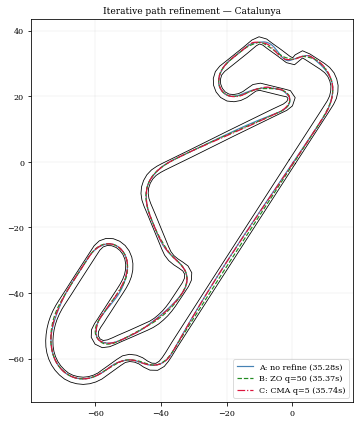

In [ ]:
# ---- Refinement raceline figure ----
rt = results['Catalunya']['reftrack']
_, _, lengths = seg_bounds(rt)
_, _, _, nv = calc_splines(
    path=np.vstack((rt[:, :2], rt[0, :2])),
    el_lengths=lengths, use_dist_scaling=True)
bound_r = np.vstack((rt[:, :2] + rt[:, 2:3] * nv, rt[0, :2] + rt[0, 2] * nv[0]))
bound_l = np.vstack((rt[:, :2] - rt[:, 3:4] * nv, rt[0, :2] - rt[0, 3] * nv[0]))

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(bound_r[:, 0], bound_r[:, 1], 'k-', lw=0.8)
ax.plot(bound_l[:, 0], bound_l[:, 1], 'k-', lw=0.8)
ax.plot(np.append(rl_a[:, 0], rl_a[0, 0]), np.append(rl_a[:, 1], rl_a[0, 1]),
        '-', color='steelblue',   lw=1.2, label=f'A: no refine ({lt_a:.2f}s)')
ax.plot(np.append(rl_b[:, 0], rl_b[0, 0]), np.append(rl_b[:, 1], rl_b[0, 1]),
        '--', color='forestgreen', lw=1.2, label=f'B: ZO q=50 ({lt_b:.2f}s)')
ax.plot(np.append(rl_c[:, 0], rl_c[0, 0]), np.append(rl_c[:, 1], rl_c[0, 1]),
        '-.', color='crimson',     lw=1.2, label=f'C: CMA q=5 ({lt_c:.2f}s)')
ax.set_title('Iterative path refinement — Catalunya')
ax.set_aspect('equal')
ax.grid(True, lw=0.3, alpha=0.5)
ax.legend(framealpha=0.7, loc='lower right')
plt.tight_layout()
fpath = os.path.join(FIG_DIR, 'fig_refinement.pdf')
plt.savefig(fpath)
print(f"\nSaved: {fpath}")
plt.show()

In [18]:
# ===========================================================================
# EXP 8 — Custom comfort cost: C_omega(alpha) = T(alpha) + omega * RMS(ax)
#
# NEW metric — RMS longitudinal acceleration: sqrt(mean(ax_profile^2))
#   Hard braking / full-throttle raises RMS ax but shortens lap time.
#   Comfort-seeking paths brake earlier and more gently — a genuine conflict
#   the black-box optimizer can navigate without any gradient information.
# ===========================================================================
print("\n" + "="*65)
print("  EXP 8: Custom comfort cost — RMS longitudinal accel (Budapest)")
print("="*65)

reftrack_bud = load_track(BENCHMARK_CIRCUITS['Budapest'], step=4)
ggv_bb, ax_max_bb = import_veh_dyn_info(GGV_PATH, AX_MAX_PATH)


def make_comfort_fn(omega, reftrack, ggv, ax_max):
    """
    cost_fn(alpha) = laptime + omega * sqrt(mean(ax_profile^2))
    RMS longitudinal acceleration [m/s^2] — NOT constrained by the GGV.
    Hard braking raises this metric; comfort-seeking paths reduce it at
    the expense of lap time, producing a visible Pareto trade-off.
    """
    from OptiLine.utils import calc_splines as _cs, create_raceline as _cr
    from OptiLine.utils import calc_head_curv_an as _hc
    from OptiLine.KinematicProfs import (
        calc_vel_profile as _vp, calc_ax_profile as _ap, calc_t_profile as _tp)

    ds_init = np.hypot(
        np.diff(np.r_[reftrack[:, 0], reftrack[0, 0]]),
        np.diff(np.r_[reftrack[:, 1], reftrack[0, 1]]))
    _, _, _M, _nv = _cs(
        path=np.vstack((reftrack[:, :2], reftrack[0, :2])),
        el_lengths=ds_init, use_dist_scaling=True)
    _cache = {}

    def cost(alpha):
        _, _, cx, cy, si_idx, tv, _, _, el = _cr(
            refline=reftrack[:, :2], normvectors=_nv,
            alpha=alpha, stepsize_interp=HYP['si'])
        _, kappa = _hc(coeffs_x=cx, coeffs_y=cy, ind_spls=si_idx, t_spls=tv)
        n = kappa.size
        if n not in _cache:
            _cache[n] = np.repeat(np.expand_dims(ggv, 0), n, 0)
        vx = _vp(ggv=ggv, ax_max_machines=ax_max,
                 v_max=VEH['v_max'], kappa=kappa, el_lengths=el,
                 closed=True, filt_window=VEH['fw'],
                 dyn_model_exp=VEH['dyn_model_exp'],
                 drag_coeff=VEH['drag_coeff'], m_veh=VEH['m_veh'],
                 p_ggv=_cache[n])
        vx_cl  = np.append(vx, vx[0])
        ax_p   = _ap(vx_profile=vx_cl, el_lengths=el, eq_length_output=False)
        t_prof = _tp(vx_profile=vx, ax_profile=ax_p, el_lengths=el)
        lt     = float(t_prof[-1])
        rms_ax = float(np.sqrt(np.mean(ax_p**2)))   # m/s^2
        return lt + omega * rms_ax
    return cost


def eval_metrics(bba, alpha):
    """Return (laptime [s], RMS ax [m/s^2], velocity profile, arc-length)."""
    s, vx, ax, kappa, t_prof, _ = bba.generate_raceline(alpha)
    lt     = float(t_prof[-1])
    rms_ax = float(np.sqrt(np.mean(ax**2)))
    return lt, rms_ax, vx, s


# ---- Sweep omega values ----
OMEGAS = [0, 1, 3, 10]
comfort_results = {}

for omega in OMEGAS:
    print(f"  omega={omega} ...", flush=True)
    lt_r, rms_r, prof_r, alpha_r = [], [], [], []

    for q in range(N_REPEATS):
        if omega == 0:
            bba = build_bba(reftrack_bud, init='mincurv',
                            n_iter=BBA_HYP['iterations'], seed=None,
                            name='Budapest')
        else:
            fn = make_comfort_fn(omega, reftrack_bud, ggv_bb, ax_max_bb)
            bba = build_bba(reftrack_bud, init='mincurv',
                            n_iter=BBA_HYP['iterations'],
                            cost_fn=fn, seed=None, name='Budapest')
        alpha, _ = bba.find_alpha(solver='ZO', verbose=False)
        lt, rms_ax, vx, s = eval_metrics(bba, alpha)
        lt_r.append(lt); rms_r.append(rms_ax)
        prof_r.append((s, vx)); alpha_r.append(alpha)
        print(f"    run {q + 1}/{N_REPEATS}: laptime={lt:.4f}s  "
              f"RMS_ax={rms_ax:.3f} m/s^2")

    lt_m, lt_sd = agg(lt_r)
    rms_m, rms_sd = agg(rms_r)
    j = median_idx(lt_r)
    comfort_results[omega] = dict(
        lt=lt_m, lt_sd=lt_sd, lt_runs=lt_r,
        rms_ax=rms_m, rms_ax_sd=rms_sd, rms_runs=rms_r,
        vx=prof_r[j][1], s=prof_r[j][0], alpha=alpha_r[j],
        prof_runs=prof_r)
    print(f"    => laptime={lt_m:.4f}+-{lt_sd:.4f}s  "
          f"RMS_ax={rms_m:.3f}+-{rms_sd:.3f} m/s^2")

# ---- MC reference ----
bba_ref = build_bba(reftrack_bud, init='mincurv', n_iter=1, seed=None, name='Budapest')
lt_mc_ref, rms_mc, vx_mc, s_mc = eval_metrics(bba_ref, bba_ref.alpha_0)
print(f"  MC ref: laptime={lt_mc_ref:.4f}s  RMS_ax={rms_mc:.3f} m/s^2")

# ---- LaTeX Table 4 ----
print("\n% ===== TABLE 4: Comfort cost sweep (Budapest) =====")
print(r"\begin{table}[t]")
print(r"  \centering")
print(r"  \caption{Speed--comfort Pareto sweep on Budapest.")
print(rf"           $\omega$ weights RMS longitudinal acceleration [m/s$^2$]."
      rf"  BBA-ZO entries are the mean over {N_REPEATS} runs $\pm$ one sample"
      rf"  standard deviation; the MC reference is deterministic.}}")
print(r"  \label{tab:comfort}")
print(r"  \begin{tabular}{lcc}")
print(r"    \toprule")
print(r"    Method ($\omega$) & Lap time (s) & RMS $a_x$ (m/s$^2$) \\")
print(r"    \midrule")
for omega in OMEGAS:
    r = comfort_results[omega]
    print(f"    BBA-ZO ($\\omega={omega}$) & {pm(r['lt'], r['lt_sd'])}"
          f" & {pm(r['rms_ax'], r['rms_ax_sd'], p=3)} \\\\")
print(f"    MC reference           & {lt_mc_ref:.2f} & {rms_mc:.3f} \\\\")
print(r"    \bottomrule")
print(r"  \end{tabular}")
print(r"\end{table}")




  EXP 8: Custom comfort cost — RMS longitudinal accel (Budapest)
  omega=0 ...


    run 1/3: laptime=33.7845s  RMS_ax=6.783 m/s^2
    run 2/3: laptime=33.7699s  RMS_ax=6.800 m/s^2
    run 3/3: laptime=33.7969s  RMS_ax=6.846 m/s^2
    => laptime=33.7838+-0.0135s  RMS_ax=6.810+-0.033 m/s^2
  omega=1 ...
    run 1/3: laptime=35.2442s  RMS_ax=4.965 m/s^2
    run 2/3: laptime=35.2871s  RMS_ax=5.121 m/s^2
    run 3/3: laptime=35.3396s  RMS_ax=4.920 m/s^2
    => laptime=35.2903+-0.0478s  RMS_ax=5.002+-0.105 m/s^2
  omega=3 ...
    run 1/3: laptime=39.8086s  RMS_ax=3.804 m/s^2
    run 2/3: laptime=40.6873s  RMS_ax=2.556 m/s^2
    run 3/3: laptime=40.1953s  RMS_ax=2.776 m/s^2
    => laptime=40.2304+-0.4404s  RMS_ax=3.046+-0.666 m/s^2
  omega=10 ...
    run 1/3: laptime=49.9639s  RMS_ax=1.269 m/s^2
    run 2/3: laptime=49.5572s  RMS_ax=1.374 m/s^2
    run 3/3: laptime=50.9128s  RMS_ax=1.270 m/s^2
    => laptime=50.1446+-0.6956s  RMS_ax=1.304+-0.061 m/s^2
  MC ref: laptime=36.6273s  RMS_ax=7.176 m/s^2

% ===== TABLE 4: Comfort cost sweep (Budapest) =====
\begin{table}[t]
  \


Saved: paper_figs/fig_comfort.pdf


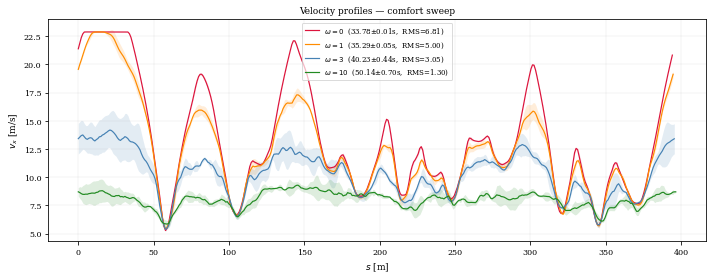

In [19]:
# ---- Figure: Pareto curve + velocity profiles ----
COLORS = {0: 'crimson', 1: 'darkorange', 3: 'steelblue', 10: 'forestgreen'}
fig, axes = plt.subplots(1, 1, figsize=(10, 4))

ax_v = axes
for w in OMEGAS:
    r = comfort_results[w]
    # each run optimises a slightly different path, so the runs are put on the
    # median run's arc length before the band is taken
    s_ref = np.asarray(r['s'], float)
    stack = []
    for s_q, v_q in r['prof_runs']:
        s_q = np.asarray(s_q, float); v_q = np.asarray(v_q, float)
        m = min(len(s_q), len(v_q))
        stack.append(np.interp(s_ref, s_q[:m], v_q[:m]))
    A = np.vstack(stack)
    mu = A.mean(axis=0)
    sd = A.std(axis=0, ddof=1) if A.shape[0] > 1 else np.zeros_like(mu)
    ax_v.plot(s_ref, mu, color=COLORS[w], lw=1.2,
              label=f'$\\omega={w}$  ({r["lt"]:.2f}$\\pm${r["lt_sd"]:.2f}s,'
                    f'  RMS={r["rms_ax"]:.2f})')
    if np.any(sd > 0):
        ax_v.fill_between(s_ref, mu - sd, mu + sd,
                          color=COLORS[w], alpha=0.15, lw=0)
ax_v.set_xlabel('$s$ [m]')
ax_v.set_ylabel('$v_x$ [m/s]')
ax_v.set_title('Velocity profiles — comfort sweep')
ax_v.legend(fontsize=7, framealpha=0.7)
ax_v.grid(True, lw=0.3, alpha=0.5)

plt.tight_layout()
fpath = os.path.join(FIG_DIR, 'fig_comfort.pdf')
plt.savefig(fpath)
print(f"\nSaved: {fpath}")
plt.show()



Saved: paper_figs/fig_pareto.pdf


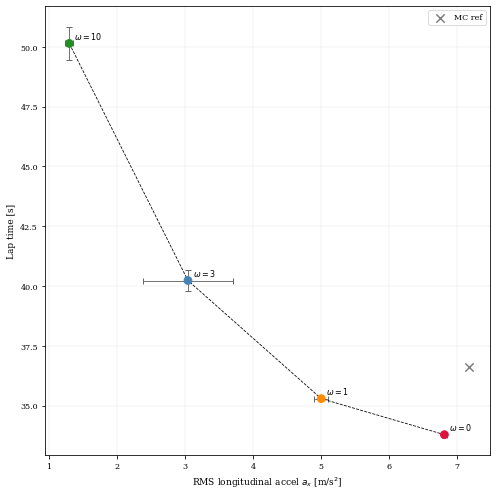

In [20]:
# ---- Figure: Pareto curve + velocity profiles ----
COLORS = {0: 'crimson', 1: 'darkorange', 3: 'steelblue', 10: 'forestgreen'}
fig, axes = plt.subplots(1, 1, figsize=(7, 7))

# Left: Pareto scatter
ax_p = axes
lts    = [comfort_results[w]['lt']     for w in OMEGAS]
rms_xs = [comfort_results[w]['rms_ax'] for w in OMEGAS]
lt_sds  = [comfort_results[w]['lt_sd']     for w in OMEGAS]
rms_sds = [comfort_results[w]['rms_ax_sd'] for w in OMEGAS]
ax_p.errorbar(rms_xs, lts, yerr=lt_sds, xerr=rms_sds,
              fmt='none', ecolor='0.4', elinewidth=0.9, capsize=3, zorder=2)
ax_p.scatter(rms_xs, lts, c=[COLORS[w] for w in OMEGAS], s=60, zorder=3)
ax_p.plot(rms_xs, lts, 'k--', lw=0.8, zorder=2)
for w, rx, lt_ in zip(OMEGAS, rms_xs, lts):
    ax_p.annotate(f'$\\omega={w}$', (rx, lt_),
                  textcoords='offset points', xytext=(5, 4), fontsize=8)
ax_p.scatter([rms_mc], [lt_mc_ref],
             marker='x', c='gray', s=70, zorder=4, label='MC ref')
ax_p.set_xlabel(r'RMS longitudinal accel $a_x$ [m/s$^2$]')
ax_p.set_ylabel('Lap time [s]')
# ax_p.set_title('speed vs comfort (Budapest)')
ax_p.legend(framealpha=0.7)
ax_p.grid(True, lw=0.3, alpha=0.5)


plt.tight_layout()
fpath = os.path.join(FIG_DIR, 'fig_pareto.pdf')
plt.savefig(fpath)
print(f"\nSaved: {fpath}")
plt.show()

Below we test QC and PQC

In [ ]:
# ===========================================================================
# EXP 9 — QC & PQC verification, all 25 circuits
#   QC    : directional FD  dd = [F(α+ε·d)−F(α)]/ε
#   PQC-DD: rank-1 gradient  ∇F ≈ (dd/‖d‖²)·d   (original approach)
# All share the same N_TEST_QC test points per circuit.
# ===========================================================================
import glob as _glob
from matplotlib.patches import Patch
from matplotlib.lines   import Line2D

ALL_CIRCUITS = {
    os.path.basename(os.path.dirname(p)): p
    for p in sorted(_glob.glob(os.path.join(MAPS_DIR, '*', '*_centerline.csv')))
}
print(f"Found {len(ALL_CIRCUITS)} circuits: {list(ALL_CIRCUITS.keys())}")

N_ITER_STAR = 2500
N_TEST_QC   = 300
EPS_FD_QC   = 1e-3
RADII_QC    = np.logspace(-1.3, 0, 15)
A_VALS_PQC  = np.array([0.00005, 0.0002]) 
SFTY_QC     = VEH['w_veh'] / 2

qc9_results = {}

for name, path in ALL_CIRCUITS.items():
    print(f"\n{'='*50}\n  {name}\n{'='*50}")
    try:

        if name == 'Berlin' or name == 'Modena':
            stp = 9
        elif name == 'Spa':
            stp = 6
        else:
            stp = 4

        reftrack    = load_track(path, step=stp)
        alpha_lb_qc = -(reftrack[:, 3] - SFTY_QC)
        alpha_ub_qc =   reftrack[:, 2] - SFTY_QC

        if name  == 'Melbourne' or name == 'Spa' or name == 'IMS' or name == 'Nuerburgring' or name == 'Monza'  or name == 'Sepang' or name == 'Sakhir':
            BBA_HYP['h'] = 0.0003
        elif name == 'Modena' or name == 'Berlin':
            BBA_HYP['h'] = 0.0008
        else:
            BBA_HYP['h'] = 0.0003

        if name == "Shanghai":
                    VEH['kappa_bound'] = 1
        else:
                    VEH['kappa_bound'] = 0.5

        print(f"  BBA-ZO {N_ITER_STAR} iters ...", flush=True)
        bba_qc = build_bba(reftrack, init='mincurv', n_iter=N_ITER_STAR, seed=None)
        alpha_star_qc, hist_star_qc = bba_qc.find_alpha(solver='ZO', verbose=False)

        def _cost_qc(alpha, _bba=bba_qc, _lb=alpha_lb_qc, _ub=alpha_ub_qc):
            try:
                _, _, _, _, tp, _ = _bba.generate_raceline(np.clip(alpha, _lb, _ub))
                return float(tp[-1])
            except Exception:
                return np.inf

        f_star_qc = _cost_qc(alpha_star_qc)
        dim_qc    = len(alpha_star_qc)
        print(f"  f*={f_star_qc:.3f}s  dim={dim_qc}  "
              f"conv: {hist_star_qc[0]:.3f}→{hist_star_qc[-1]:.3f}s")

        g_qc      = [];  n_viol_qc = 0;  n_skip_qc = 0
        g_pqc_dd  = {a: [] for a in A_VALS_PQC};  nv_pqc_dd = {a: 0 for a in A_VALS_PQC}
        # np.random.seed(7)

        for k in range(N_TEST_QC):
            direction = np.random.randn(dim_qc)
            direction /= np.linalg.norm(direction)
            r       = RADII_QC[k % len(RADII_QC)]
            alpha_k = np.clip(alpha_star_qc + r * direction, alpha_lb_qc, alpha_ub_qc)

            f_k = _cost_qc(alpha_k)
            gap = f_k - f_star_qc
            if gap < 1e-14:
                n_skip_qc += 1; continue
            d_vec = alpha_star_qc - alpha_k
            d_sq  = float(np.dot(d_vec, d_vec))
            if d_sq < 1e-20:
                n_skip_qc += 1; continue

            # QC: directional FD
            f_pert = _cost_qc(alpha_k + EPS_FD_QC * d_vec)
            if not np.isfinite(f_pert):
                n_skip_qc += 1; continue
            dd = (f_pert - f_k) / EPS_FD_QC
            if dd >= 0:
                n_viol_qc += 1; g_qc.append(np.nan)
            else:
                g_qc.append(abs(dd) / gap)

            # PQC-DD: rank-1  ∇F ≈ (dd/‖d‖²)·d
            grad_r1 = (dd / d_sq) * d_vec
            for a_val in A_VALS_PQC:
                z     = np.clip(alpha_k - a_val * grad_r1, alpha_lb_qc, alpha_ub_qc)
                Q_l   = (alpha_k - z) / a_val
                inner = float(np.dot(Q_l, d_vec))
                if inner >= 0:
                    nv_pqc_dd[a_val] += 1; g_pqc_dd[a_val].append(np.nan)
                else:
                    g_pqc_dd[a_val].append(abs(inner) / gap)


        g_qc_arr     = np.array(g_qc, dtype=float)
        valid_qc     = ~np.isnan(g_qc_arr)
        g_qc_ok      = g_qc_arr[valid_qc]
        g_pqc_dd_arr = {a: np.array(g_pqc_dd[a], dtype=float) for a in A_VALS_PQC}

        gs_qc = g_qc_ok.min()  if len(g_qc_ok) else np.nan
        mn_qc = g_qc_ok.mean() if len(g_qc_ok) else np.nan
        print(f"\n  {'Method':<12} {'a':>7} {'γ*':>9} {'mean γ':>9} {'median γ':>10} {'viol/chk':>10}")
        print(f"  {'-'*60}")
        print(f"  {'QC':12s} {'—':>7} {gs_qc:>9.4f} {mn_qc:>9.4f} "
              f"{np.median(g_qc_ok) if len(g_qc_ok) else np.nan:>10.4f} "
              f"{n_viol_qc:>4}/{len(g_qc_arr)}")
        print(f"  {'-'*60}")

        gs_pqc_dd = {}
        for a in A_VALS_PQC:
            ok_dd = g_pqc_dd_arr[a][~np.isnan(g_pqc_dd_arr[a])]
            gs_dd = ok_dd.min()  if len(ok_dd) else np.nan
            mn_dd = ok_dd.mean() if len(ok_dd) else np.nan
            print(f"  {'PQC-DD':12s} {a:>7.6f} {gs_dd:>9.4f} {mn_dd:>9.4f} "
                  f"{np.median(ok_dd) if len(ok_dd) else np.nan:>10.4f} "
                  f"{nv_pqc_dd[a]:>4}/{len(g_pqc_dd_arr[a])}")
            print()

        qc9_results[name] = dict(
            hist_star=hist_star_qc, f_star=f_star_qc, dim=dim_qc,
            g_qc=g_qc_arr, valid_qc=valid_qc,
            n_viol_qc=n_viol_qc, n_skip_qc=n_skip_qc, gamma_star_qc=gs_qc,
            g_pqc_dd=g_pqc_dd_arr, nv_pqc_dd=nv_pqc_dd, gamma_star_pqc_dd=gs_pqc_dd
        )

    except Exception as e:
        print(f"  ERROR: {e}"); qc9_results[name] = None

n_ok = sum(v is not None for v in qc9_results.values())
print(f"\n{'='*65}\n  EXP 9 complete: {n_ok}/{len(ALL_CIRCUITS)} succeeded.\n{'='*65}")



Found 25 circuits: ['Austin', 'Berlin', 'BrandsHatch', 'Budapest', 'Catalunya', 'Hockenheim', 'IMS', 'Melbourne', 'MexicoCity', 'Modena', 'Montreal', 'Monza', 'MoscowRaceway', 'Nuerburgring', 'Oschersleben', 'Sakhir', 'SaoPaulo', 'Sepang', 'Shanghai', 'Silverstone', 'Sochi', 'Spa', 'Spielberg', 'YasMarina', 'Zandvoort']

  Austin
  BBA-ZO 2500 iters ...
  f*=36.950s  dim=276  conv: 41.436→36.950s

  Method             a        γ*    mean γ   median γ   viol/chk
  ------------------------------------------------------------
  QC                 —    0.8178    1.4005     1.3417    0/300
  ------------------------------------------------------------
  PQC-DD       0.000050    0.8178    1.4005     1.3417    0/300

  PQC-DD       0.000200    0.8178    1.4005     1.3417    0/300


  Berlin
  BBA-ZO 2500 iters ...
  f*=107.277s  dim=263  conv: 107.951→107.277s

  Method             a        γ*    mean γ   median γ   viol/chk
  ------------------------------------------------------------
  QC 

Saved: fig_qc_convergence.pdf


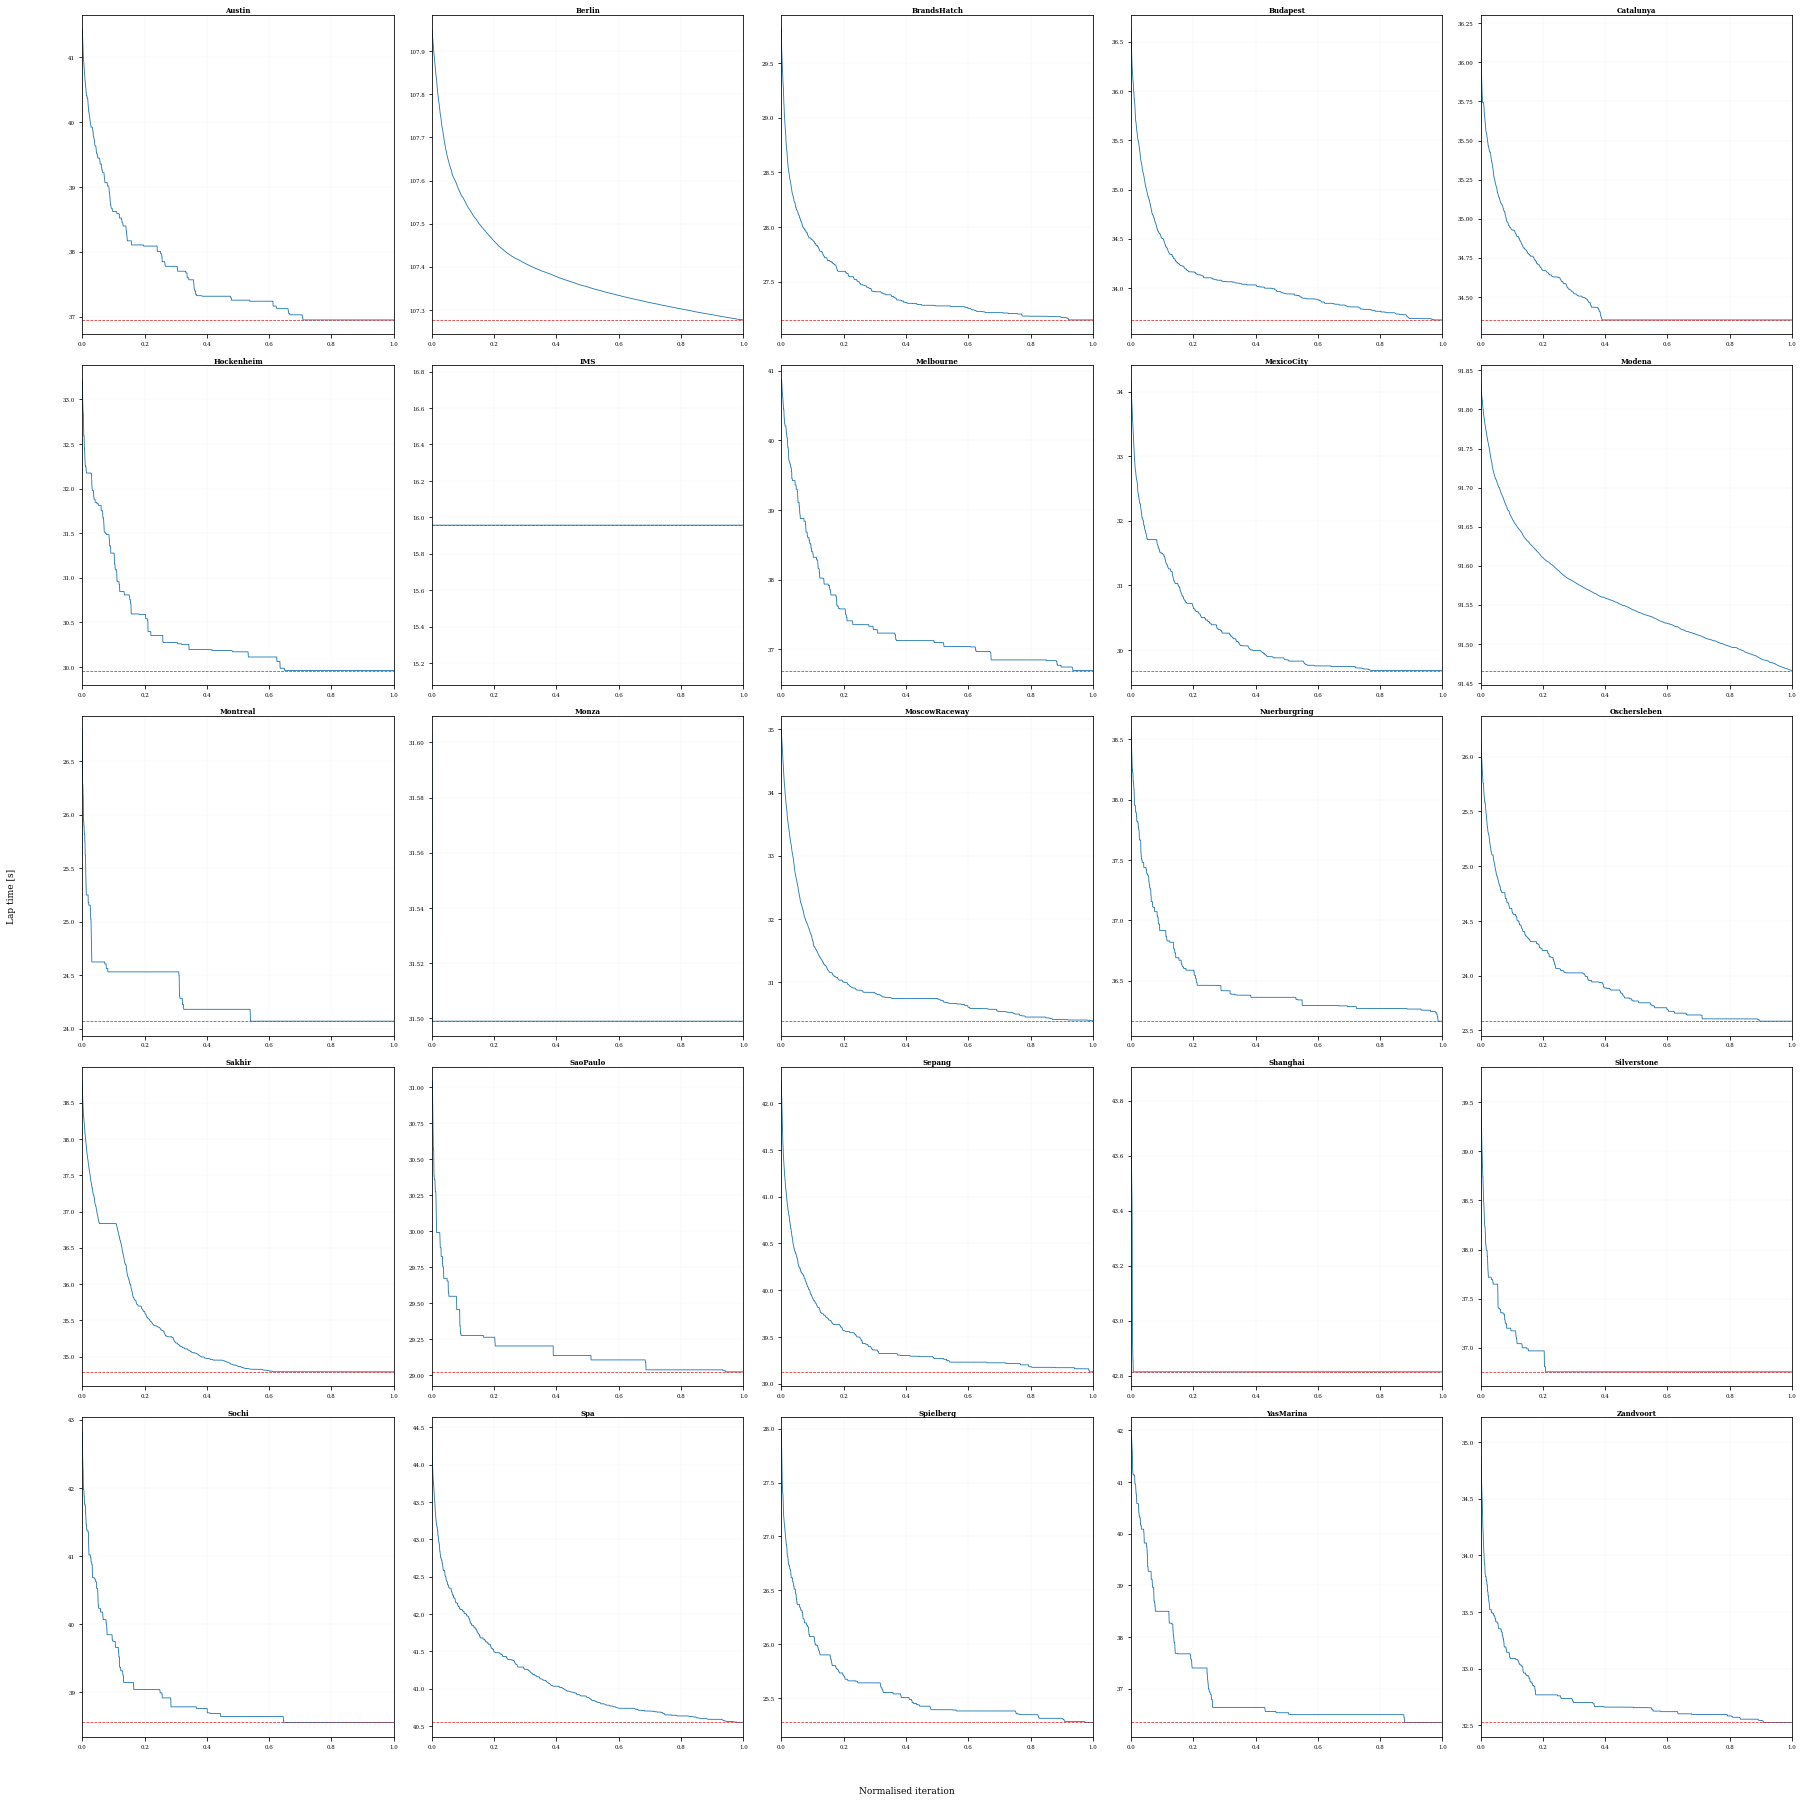

Saved: fig_qc_summary.pdf


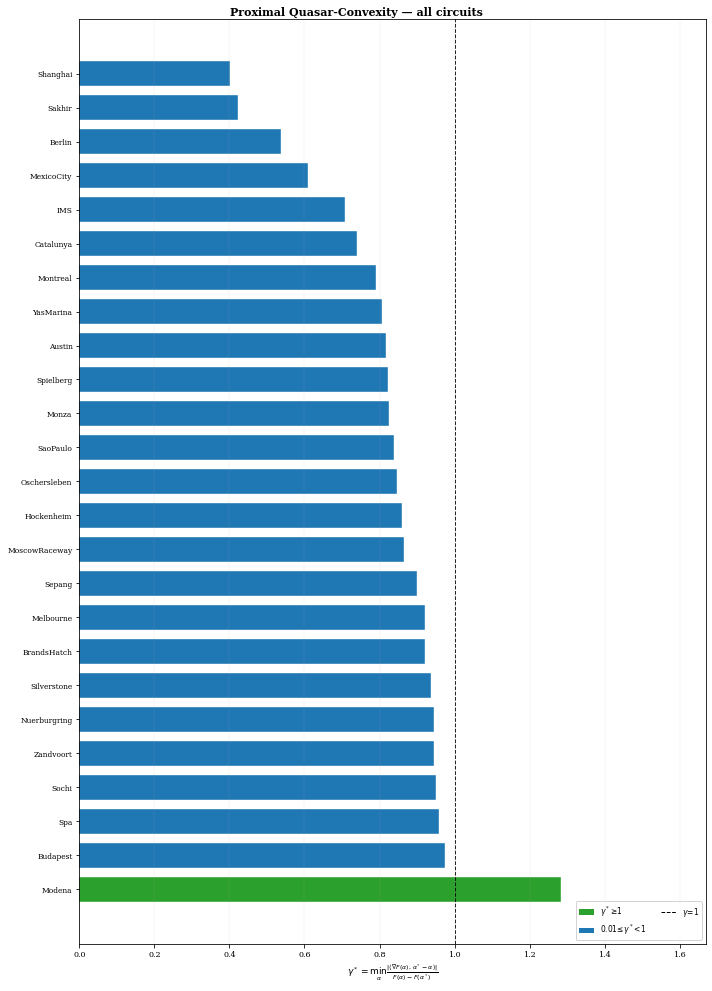

Saved: fig_qc_histograms.pdf


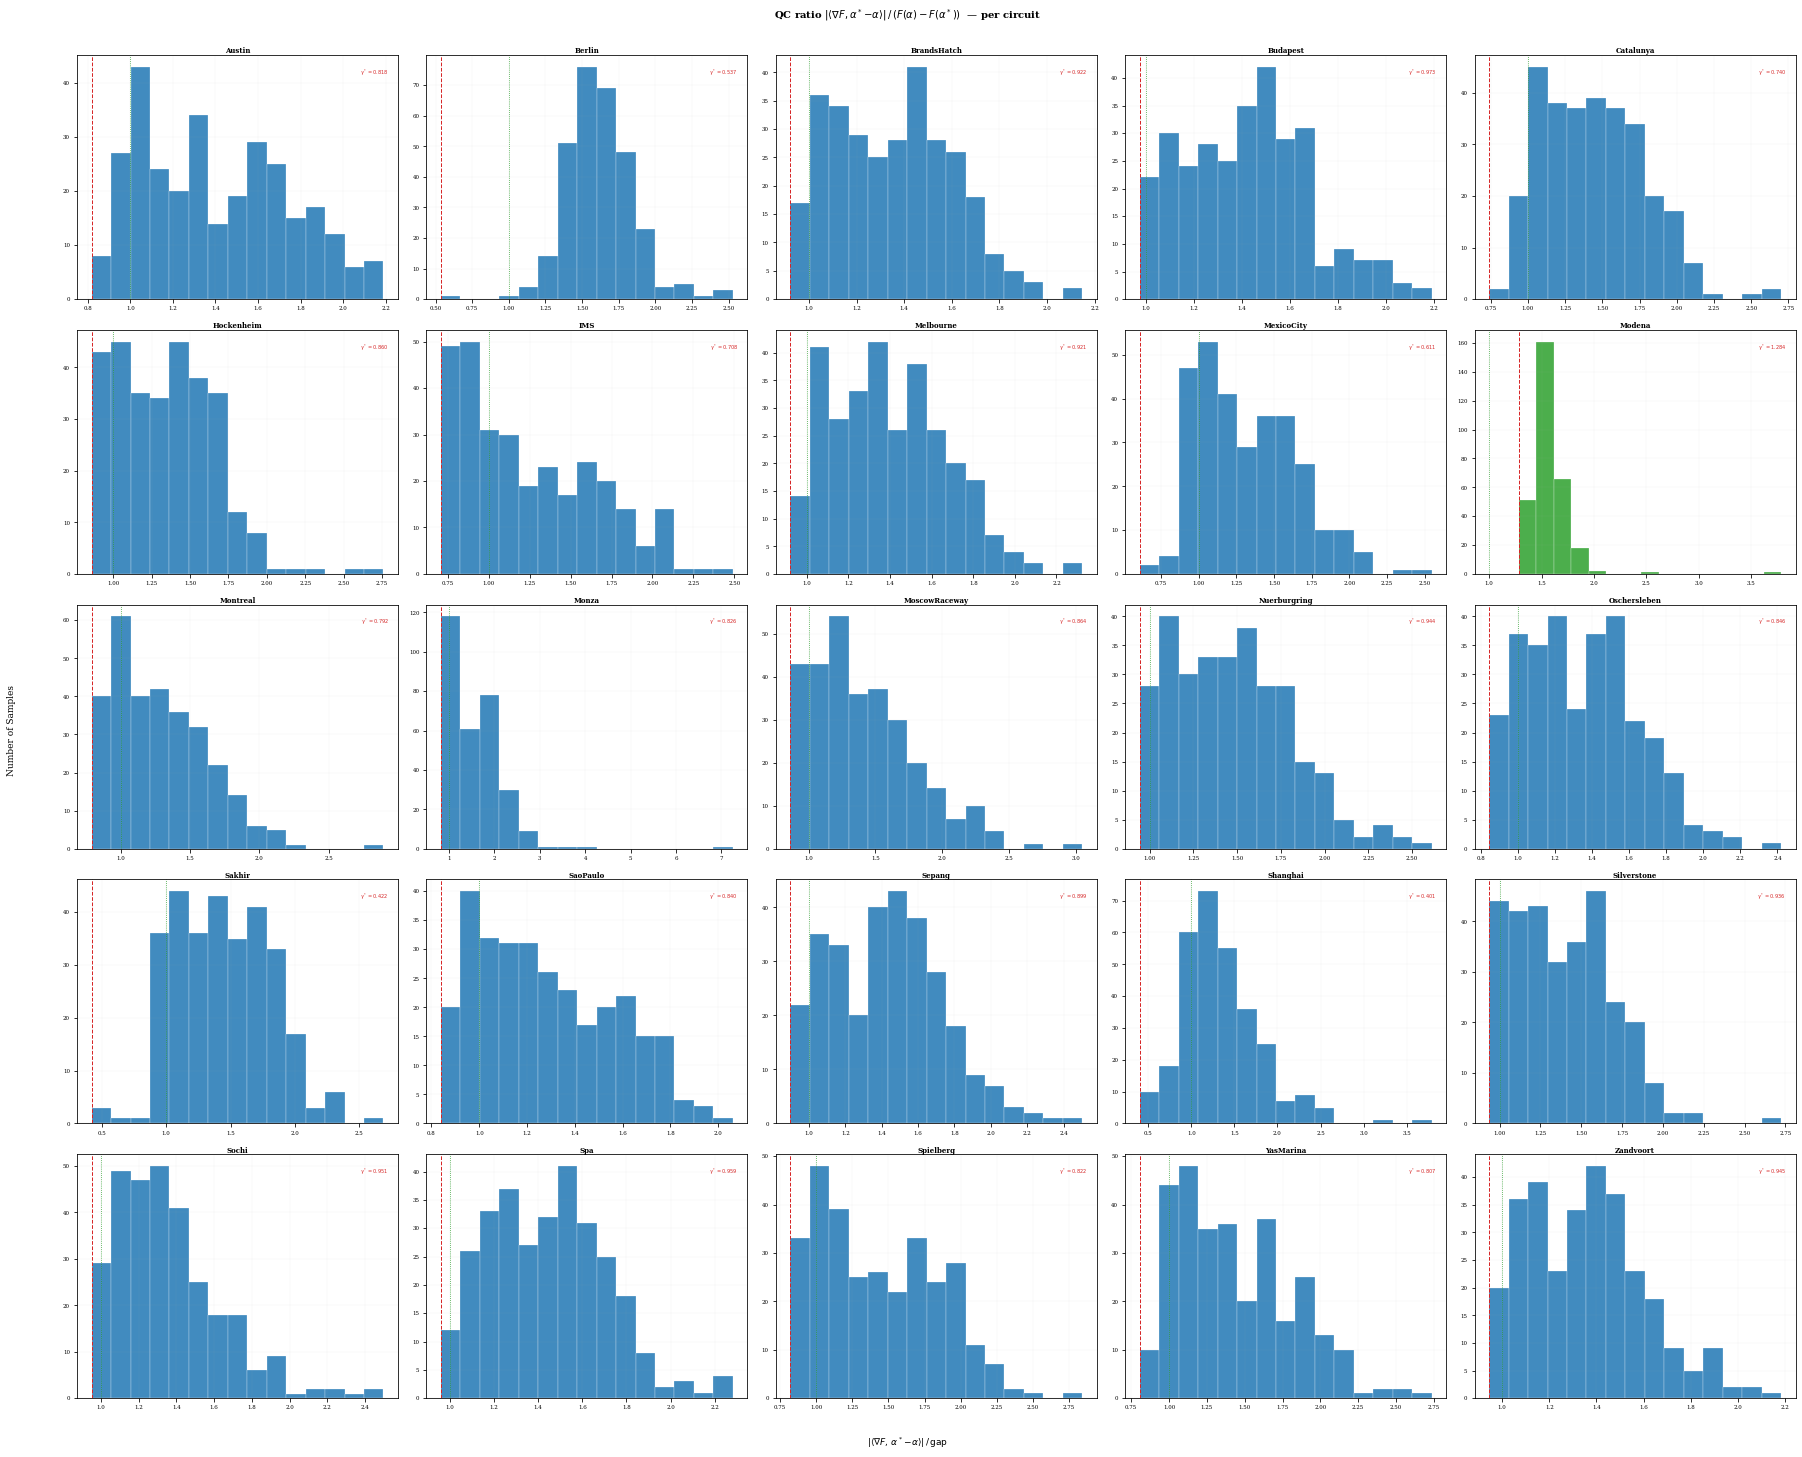

In [ ]:
# ── plots ──────────────────────────────────────────────────────────────────
from matplotlib.patches import Patch
from matplotlib.lines   import Line2D

_valid  = {k: v for k, v in qc9_results.items() if v is not None}
_names  = list(_valid.keys())
N_C     = len(_names)
NCOLS_C = 5
NROWS_C = int(np.ceil(N_C / NCOLS_C))
gs_all  = np.array([_valid[n]['gamma_star_qc'] for n in _names])
srt     = np.argsort(gs_all)[::-1]
snames  = [_names[i] for i in srt]

def _gc(g):
    if np.isnan(g): return '#aaaaaa'
    if g >= 1.0:    return '#2ca02c'
    if g >= 0.01:    return '#1f77b4'
    return                 '#d62728'

# Fig 1 — convergence grid
fig1, axes1 = plt.subplots(NROWS_C, NCOLS_C,
                            figsize=(5*NCOLS_C, 5*NROWS_C))
# fig1.suptitle(rf'BBA-ZO convergence  ({N_ITER_STAR} iters, mincurv init)',
#               fontsize=10, fontweight='bold', y=1.002)
for idx, name in enumerate(_names):
    ax = axes1[idx//NCOLS_C, idx%NCOLS_C]
    res = _valid[name]
    ax.plot(np.linspace(0, 1, len(res['hist_star'])), res['hist_star'],
            color='#1f77b4', lw=0.85)
    ax.axhline(res['f_star'], color='#d62728', lw=0.75, ls='--')
    ax.set_title(name, fontsize=7, fontweight='bold', pad=2)
    ax.tick_params(labelsize=5.5); ax.grid(True, lw=0.2, alpha=0.35); ax.set_xlim(0, 1)
    # ax.text(0.97, 0.95, f"$f^*={res['f_star']:.1f}$s", transform=ax.transAxes,
    #         fontsize=5, ha='right', va='top', color='#d62728')
for idx in range(N_C, NROWS_C*NCOLS_C):
    axes1[idx//NCOLS_C, idx%NCOLS_C].set_visible(False)
fig1.text(0.5, 0.00, 'Normalised iteration', ha='center', va='bottom', fontsize=9)
fig1.text(0.00, 0.5, 'Lap time [s]', va='center', ha='left', rotation='vertical', fontsize=9)
plt.tight_layout(rect=[0.025, 0.02, 1.0, 1.0])
plt.savefig(os.path.join(FIG_DIR, 'fig_qc_convergence.pdf'), bbox_inches='tight')
print("Saved: fig_qc_convergence.pdf"); plt.show()

# Fig 2 — QC bar chart only
viol_all = np.array([_valid[n]['n_viol_qc'] for n in _names])
chk_all  = np.array([_valid[n]['valid_qc'].sum() + _valid[n]['n_viol_qc'] for n in _names])
sgs = gs_all[srt]; sviols = viol_all[srt]; schk = chk_all[srt]
fig2, ax_b = plt.subplots(figsize=(10, max(5, 0.5*N_C+1.5)))
fig2.suptitle('Proximal Quasar-Convexity — all circuits', fontsize=11, fontweight='bold')
y_pos = np.arange(N_C)
ax_b.barh(y_pos, sgs, color=[_gc(g) for g in sgs], edgecolor='white', lw=0.4, height=0.72)
ax_b.axvline(1.0, color='k', lw=1.0, ls='--', alpha=0.85)
ax_b.set_yticks(y_pos); ax_b.set_yticklabels(snames, fontsize=7.5)
ax_b.set_xlabel(
    r'$\gamma^* = \min_\alpha'
    r'\frac{|\langle\nabla F(\alpha),\,\alpha^*-\alpha\rangle|}{F(\alpha)-F(\alpha^*)}$',
    fontsize=9)
# ax_b.set_title(r'QC $\gamma^*$ per circuit (descending)', fontsize=9)
ax_b.grid(True, axis='x', lw=0.3, alpha=0.4)
xmax_b = np.nanmax(sgs) if not np.all(np.isnan(sgs)) else 2.0
ax_b.set_xlim(0, xmax_b*1.30)
# for i, (g, v, c) in enumerate(zip(sgs, sviols, schk)):
#     if not np.isnan(g):
#         ax_b.text(g + xmax_b*0.015, i, f'{v}/{c}',
#                   va='center', fontsize=5.5, color='#555555')
ax_b.legend(handles=[
    Patch(facecolor='#2ca02c', label=r'$\gamma^*\!\geq\!1$'),
    Patch(facecolor='#1f77b4', label=r'$0.01\!\leq\!\gamma^*\!<\!1$'),
    # Patch(facecolor='#d62728', label=r'$\gamma^*\!<\!0.01$'),
    Line2D([0], [0], color='k', lw=1, ls='--', label=r'$\gamma\!=\!1$'),
], fontsize=7.5, loc='lower right', framealpha=0.85, ncol=2)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_qc_summary.pdf'), bbox_inches='tight')
print("Saved: fig_qc_summary.pdf"); plt.show()

# Fig 2b — per-map QC ratio histograms  (same layout as convergence grid)
fig2b, axes2b = plt.subplots(NROWS_C, NCOLS_C,
                              figsize=(5*NCOLS_C, 4*NROWS_C))
fig2b.suptitle(
    r'QC ratio $|\langle\nabla F,\alpha^*\!-\!\alpha\rangle|\,/\,(F(\alpha)-F(\alpha^*))$'
    '  — per circuit',
    fontsize=10, fontweight='bold', y=1.002)

for idx, name in enumerate(_names):
    ax  = axes2b[idx//NCOLS_C, idx%NCOLS_C]
    res = _valid[name]
    ok  = res['g_qc'][res['valid_qc']]
    gs  = res['gamma_star_qc']

    if len(ok):
        ax.hist(ok, bins=15, color=_gc(gs), edgecolor='white', lw=0.3,
                density=False, alpha=0.85)
        ax.axvline(gs, color='#d62728', lw=1.0, ls='--')
    ax.axvline(1.0, color='#2ca02c', lw=0.8, ls=':')
    ax.set_title(name, fontsize=7, fontweight='bold', pad=2)
    ax.tick_params(labelsize=5.5); ax.grid(True, lw=0.2, alpha=0.35)

    viol = res['n_viol_qc']
    chk  = res['valid_qc'].sum() + viol
    label = (f"$\\gamma^*={gs:.3f}$" if not np.isnan(gs) else "no valid pts")
    ax.text(0.97, 0.95, label,
            transform=ax.transAxes, fontsize=5,
            ha='right', va='top', color='#d62728')
    # ax.text(0.97, 0.80, f'viol={viol}/{chk}',
    #         transform=ax.transAxes, fontsize=4.5,
    #         ha='right', va='top', color='#555555')

for idx in range(N_C, NROWS_C*NCOLS_C):
    axes2b[idx//NCOLS_C, idx%NCOLS_C].set_visible(False)

fig2b.text(0.5,  0.00, r'$|\langle\nabla F,\,\alpha^*\!-\!\alpha\rangle|\,/\,\mathrm{gap}$',
           ha='center', va='bottom', fontsize=9)
fig2b.text(0.00, 0.5,  'Number of Samples', va='center', ha='left',
           rotation='vertical', fontsize=9)
plt.tight_layout(rect=[0.025, 0.02, 1.0, 1.0])
plt.savefig(os.path.join(FIG_DIR, 'fig_qc_histograms.pdf'), bbox_inches='tight')
print("Saved: fig_qc_histograms.pdf"); plt.show()


In [ ]:
CIRCUITS = {
    "Shanghai":     os.path.join(MAPS_DIR, "Shanghai",     "Shanghai_centerline.csv"),
    "MoscowRaceway":     os.path.join(MAPS_DIR, "MoscowRaceway",     "MoscowRaceway_centerline.csv"),
    "Silverstone":     os.path.join(MAPS_DIR, "Silverstone",     "Silverstone_centerline.csv"),
}


N_ITER_STAR = 3000
N_TEST_QC   = 300
EPS_FD_QC   = 1e-3
RADII_QC    = np.logspace(-1.2, 0, 15)
A_VALS_PQC  = np.array([0.00001, 0.0001]) 
SFTY_QC     = VEH['w_veh'] / 2


for name, path in CIRCUITS.items():
    print(f"\n{'='*50}\n  {name}\n{'='*50}")
    try:

        if name == 'Berlin' or name == 'Modena':
            stp = 9
        elif name == 'Spa':
            stp = 6
        else:
            stp = 4

        reftrack    = load_track(path, step=stp)
        alpha_lb_qc = -(reftrack[:, 3] - SFTY_QC)
        alpha_ub_qc =   reftrack[:, 2] - SFTY_QC

        BBA_HYP['h'] = 0.0003

        if name == "Shanghai":
            VEH['kappa_bound'] = 1
        else:
            VEH['kappa_bound'] = 0.5

        print(f"  BBA-ZO {N_ITER_STAR} iters ...", flush=True)
        bba_qc = build_bba(reftrack, init='mincurv', n_iter=N_ITER_STAR, seed=None)
        alpha_star_qc, hist_star_qc = bba_qc.find_alpha(solver='ZO', verbose=False)

        def _cost_qc(alpha, _bba=bba_qc, _lb=alpha_lb_qc, _ub=alpha_ub_qc):
            try:
                _, _, _, _, tp, _ = _bba.generate_raceline(np.clip(alpha, _lb, _ub))
                return float(tp[-1])
            except Exception:
                return np.inf

        f_star_qc = _cost_qc(alpha_star_qc)
        dim_qc    = len(alpha_star_qc)
        print(f"  f*={f_star_qc:.3f}s  dim={dim_qc}  "
              f"conv: {hist_star_qc[0]:.3f}→{hist_star_qc[-1]:.3f}s")

        g_qc      = [];  n_viol_qc = 0;  n_skip_qc = 0
        g_pqc_dd  = {a: [] for a in A_VALS_PQC};  nv_pqc_dd = {a: 0 for a in A_VALS_PQC}

        for k in range(N_TEST_QC):
            direction = np.random.randn(dim_qc)
            direction /= np.linalg.norm(direction)
            r       = RADII_QC[k % len(RADII_QC)]
            alpha_k = np.clip(alpha_star_qc + r * direction, alpha_lb_qc, alpha_ub_qc)

            f_k = _cost_qc(alpha_k)
            gap = f_k - f_star_qc
            if gap < 1e-14:
                n_skip_qc += 1; continue
            d_vec = alpha_star_qc - alpha_k
            d_sq  = float(np.dot(d_vec, d_vec))
            if d_sq < 1e-20:
                n_skip_qc += 1; continue

            # QC: directional FD
            f_pert = _cost_qc(alpha_k + EPS_FD_QC * d_vec)
            if not np.isfinite(f_pert):
                n_skip_qc += 1; continue
            dd = (f_pert - f_k) / EPS_FD_QC
            if dd >= 0:
                n_viol_qc += 1; g_qc.append(np.nan)
            else:
                g_qc.append(abs(dd) / gap)

            # PQC-DD: rank-1  ∇F ≈ (dd/‖d‖²)·d
            grad_r1 = (dd / d_sq) * d_vec
            for a_val in A_VALS_PQC:
                z     = np.clip(alpha_k - a_val * grad_r1, alpha_lb_qc, alpha_ub_qc)
                Q_l   = (alpha_k - z) / a_val
                inner = float(np.dot(Q_l, d_vec))
                if inner >= 0:
                    nv_pqc_dd[a_val] += 1; g_pqc_dd[a_val].append(np.nan)
                else:
                    g_pqc_dd[a_val].append(abs(inner) / gap)


        g_qc_arr     = np.array(g_qc, dtype=float)
        valid_qc     = ~np.isnan(g_qc_arr)
        g_qc_ok      = g_qc_arr[valid_qc]
        g_pqc_dd_arr = {a: np.array(g_pqc_dd[a], dtype=float) for a in A_VALS_PQC}

        gs_qc = g_qc_ok.min()  if len(g_qc_ok) else np.nan
        mn_qc = g_qc_ok.mean() if len(g_qc_ok) else np.nan
        print(f"\n  {'Method':<12} {'a':>7} {'γ*':>9} {'mean γ':>9} {'median γ':>10} {'viol/chk':>10}")
        print(f"  {'-'*60}")
        print(f"  {'QC':12s} {'—':>7} {gs_qc:>9.4f} {mn_qc:>9.4f} "
              f"{np.median(g_qc_ok) if len(g_qc_ok) else np.nan:>10.4f} "
              f"{n_viol_qc:>4}/{len(g_qc_arr)}")
        print(f"  {'-'*60}")

        gs_pqc_dd = {}
        for a in A_VALS_PQC:
            ok_dd = g_pqc_dd_arr[a][~np.isnan(g_pqc_dd_arr[a])]
            gs_dd = ok_dd.min()  if len(ok_dd) else np.nan
            mn_dd = ok_dd.mean() if len(ok_dd) else np.nan
            print(f"  {'PQC-DD':12s} {a:>7.6f} {gs_dd:>9.4f} {mn_dd:>9.4f} "
                  f"{np.median(ok_dd) if len(ok_dd) else np.nan:>10.4f} "
                  f"{nv_pqc_dd[a]:>4}/{len(g_pqc_dd_arr[a])}")
            print()

        qc9_results[name] = dict(
            hist_star=hist_star_qc, f_star=f_star_qc, dim=dim_qc,
            g_qc=g_qc_arr, valid_qc=valid_qc,
            n_viol_qc=n_viol_qc, n_skip_qc=n_skip_qc, gamma_star_qc=gs_qc,
            g_pqc_dd=g_pqc_dd_arr, nv_pqc_dd=nv_pqc_dd, gamma_star_pqc_dd=gs_pqc_dd
        )

    except Exception as e:
        print(f"  ERROR: {e}"); qc9_results[name] = None





  Shanghai
  BBA-ZO 3000 iters ...
  f*=42.814s  dim=272  conv: 43.872→42.814s

  Method             a        γ*    mean γ   median γ   viol/chk
  ------------------------------------------------------------
  QC                 —    0.4012    1.3445     1.2696    0/300
  ------------------------------------------------------------
  PQC-DD       0.000010    0.4012    1.3445     1.2696    0/300

  PQC-DD       0.000100    0.4012    1.3445     1.2696    0/300


  MoscowRaceway
  BBA-ZO 3000 iters ...
  f*=30.385s  dim=203  conv: 34.984→30.385s

  Method             a        γ*    mean γ   median γ   viol/chk
  ------------------------------------------------------------
  QC                 —    0.8645    1.4128     1.3569    0/300
  ------------------------------------------------------------
  PQC-DD       0.000010    0.8645    1.4128     1.3569    0/300

  PQC-DD       0.000100    0.8645    1.4128     1.3569    0/300


  Silverstone
  BBA-ZO 3000 iters ...
  f*=36.756s  dim=294  con

In [ ]:
# ===========================================================================
# Save the QC/PQC run (EXP 9) results to disk before closing the session.
# The run kept per-map QC/PQC data in `qc9_results` (convergence history,
# f_star, and the gamma arrays) but NOT the per-map optimal alpha / trajectory
# (those were overwritten each loop). Only the LAST executed map's alpha /
# reftrack survive in memory. We save everything that is available.
# ===========================================================================
import os, json, pickle, datetime
import numpy as np

_OUT = "QC_PQC_results"
os.makedirs(_OUT, exist_ok=True)
_stamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
assert 'qc9_results' in globals(), "qc9_results not in kernel - run the QC/PQC cell first!"

# 1) full results dict (the main artifact) ----------------------------------
with open(os.path.join(_OUT, "qc9_results.pkl"), "wb") as _f:
    pickle.dump(qc9_results, _f)

# 2) run configuration -------------------------------------------------------
_cfg = dict(
    N_ITER_STAR=globals().get('N_ITER_STAR'), N_TEST_QC=globals().get('N_TEST_QC'),
    EPS_FD_QC=globals().get('EPS_FD_QC'),
    RADII_QC=np.asarray(globals().get('RADII_QC', [])).tolist(),
    A_VALS_PQC=np.asarray(globals().get('A_VALS_PQC', [])).tolist(),
    SFTY_QC=globals().get('SFTY_QC'), VEH=globals().get('VEH'), saved_at=_stamp,
    note="per-map alpha*/trajectory not retained by the run; only qc9_results + last-map alpha saved.",
)
with open(os.path.join(_OUT, "qc9_config.json"), "w") as _f:
    json.dump(_cfg, _f, indent=2, default=str)

# 3) per-map convergence histories -> npz -----------------------------------
_hist = {_n: np.asarray(_r['hist_star'], float)
         for _n, _r in qc9_results.items() if _r is not None and 'hist_star' in _r}
np.savez(os.path.join(_OUT, "qc9_histories.npz"), **_hist)

# 4) readable per-map summary CSV (gammas recomputed from the stored arrays) --
_avals = list(np.asarray(globals().get('A_VALS_PQC', [])))
_hdr = "map,ok,dim,f_star,hist_first,hist_last,gamma_star_qc,qc_viol,qc_checks"
_hdr += "".join(f",pqc_gstar_a{_a:g},pqc_viol_a{_a:g}" for _a in _avals)
_lines = [_hdr]
for _n, _r in qc9_results.items():
    if _r is None:
        _lines.append(f"{_n},0" + ","*(_hdr.count(",")-1)); continue
    _gq = np.asarray(_r.get('g_qc', []), float); _gqok = _gq[np.isfinite(_gq)]
    _row = [_n, 1, _r.get('dim', ''), f"{_r.get('f_star', float('nan')):.4f}",
            f"{_r['hist_star'][0]:.4f}" if len(_r.get('hist_star', [])) else "",
            f"{_r['hist_star'][-1]:.4f}" if len(_r.get('hist_star', [])) else "",
            f"{(_gqok.min() if len(_gqok) else float('nan')):.4f}",
            _r.get('n_viol_qc', ''), int(_gq.size)]
    _gpd = _r.get('g_pqc_dd', {}); _nvd = _r.get('nv_pqc_dd', {})
    for _a in _avals:
        _arr = np.asarray(_gpd.get(_a, []), float); _ok = _arr[np.isfinite(_arr)]
        _row += [f"{(_ok.min() if len(_ok) else float('nan')):.4f}", _nvd.get(_a, '')]
    _lines.append(",".join(str(_x) for _x in _row))
with open(os.path.join(_OUT, "qc9_summary.csv"), "w") as _f:
    _f.write("\n".join(_lines) + "\n")

# 5) last-in-memory map's alpha* + reconstructed trajectory (single map only) -
if 'alpha_star_qc' in globals() and 'reftrack' in globals():
    _pack = dict(last_map_name=str(globals().get('name', 'unknown')),
                 alpha_star=np.asarray(alpha_star_qc, float),
                 reftrack=np.asarray(reftrack, float))
    try:
        if 'bba_qc' in globals():
            _lb, _ub = globals().get('alpha_lb_qc'), globals().get('alpha_ub_qc')
            _a0 = np.clip(alpha_star_qc, _lb, _ub) if _lb is not None else alpha_star_qc
            _s, _vx, _ax, _kap, _tp, _rl = bba_qc.generate_raceline(_a0)
            _pack.update(dict(raceline_xy=np.asarray(_rl, float), s=np.asarray(_s, float),
                              vx=np.asarray(_vx, float), ax=np.asarray(_ax, float),
                              kappa=np.asarray(_kap, float), t_profile=np.asarray(_tp, float),
                              laptime=float(_tp[-1])))
    except Exception as _e:
        _pack['reconstruct_error'] = str(_e)
    np.savez(os.path.join(_OUT, "qc9_last_map_solution.npz"), **_pack)

# report ---------------------------------------------------------------------
print("Saved to", os.path.abspath(_OUT))
for _fn in sorted(os.listdir(_OUT)):
    print(f"  - {_fn}  ({os.path.getsize(os.path.join(_OUT, _fn))} bytes)")
print(f"\nqc9_results: {sum(_v is not None for _v in qc9_results.values())}/{len(qc9_results)} maps saved.")
print("NOTE: per-map alpha*/trajectory were NOT retained by the run; only qc9_results")
print("      (histories + f_star + gamma arrays) + the LAST map's alpha/trajectory are saved.")

Saved to /home/amirali/RA-L Optiline/QC_PQC_results
  - qc9_config.json  (801 bytes)
  - qc9_histories.npz  (518426 bytes)
  - qc9_last_map_solution.npz  (39610 bytes)
  - qc9_results.pkl  (708344 bytes)
  - qc9_summary.csv  (1718 bytes)

qc9_results: 25/25 maps saved.
NOTE: per-map alpha*/trajectory were NOT retained by the run; only qc9_results
      (histories + f_star + gamma arrays) + the LAST map's alpha/trajectory are saved.
